<a href="https://colab.research.google.com/github/Cmay487/Premier_League_Match_Prediction/blob/UpdatedWorkbook_0308/ApplyingProbabilityToFootball.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📄 Notes on the Data


---

## ⚽ Key to Results Data

| Column | Description |
|--------|-------------|
| **Div** | League Division |
| **Date** | Match Date (dd/mm/yy) |
| **Time** | Time of match kick-off |
| **HomeTeam** | Home Team |
| **AwayTeam** | Away Team |
| **FTHG / HG** | Full Time Home Team Goals |
| **FTAG / AG** | Full Time Away Team Goals |
| **FTR / Res** | Full Time Result (`H` = Home Win, `D` = Draw, `A` = Away Win) |
| **HTHG** | Half Time Home Team Goals |
| **HTAG** | Half Time Away Team Goals |
| **HTR** | Half Time Result (`H` = Home Win, `D` = Draw, `A` = Away Win) |

---

## 📊 Match Statistics (where available)

| Column | Description |
|--------|-------------|
| **Attendance** | Crowd Attendance |
| **Referee** | Match Referee |
| **HS / AS** | Home / Away Shots |
| **HST / AST** | Home / Away Shots on Target |
| **HHW / AHW** | Home / Away Hit Woodwork |
| **HC / AC** | Home / Away Corners |
| **HF / AF** | Home / Away Fouls Committed |
| **HFKC / AFKC** | Home / Away Free Kicks Conceded |
| **HO / AO** | Home / Away Offsides |
| **HY / AY** | Home / Away Yellow Cards |
| **HR / AR** | Home / Away Red Cards |
| **HBP / ABP** | Home / Away Bookings Points (10 = yellow, 25 = red) |

> **Note 1:** Free Kicks Conceded includes fouls, offsides, and any other offence committed, and will always be equal to or higher than the number of fouls.  
> **Note 2:** English and Scottish yellow cards do not include the initial yellow when a second is shown that becomes a red (European games include it).

---

## 💰 Betting Odds Data (Pre-Closing Odds)

### Bookmaker Codes

| Code | Description |
|------|-------------|
| **B365H / B365D / B365A** | Bet365 home/draw/away odds |


# 📄 Section Notes
---



# Libraries

In [568]:
pip install catboost

In [8]:
# funcs
from utils.get_data import extractWebData

# standard libraries for EDA
import scipy.stats as stats
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from scipy.stats import (
    binom, beta, poisson, expon, geom, nbinom,
    chi2_contingency
)
warnings.filterwarnings('ignore')

# web scraping
from bs4 import BeautifulSoup
import requests

# machine learning
from catboost import CatBoostClassifier, Pool
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score


# cross validation for time series
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

# cross validation scoring
from sklearn.model_selection import cross_val_score

# ML Preprocessing
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# pca
from sklearn.decomposition import PCA

# feature selection
from sklearn.feature_selection import RFE

# set sns theme
sns.set_theme(style="whitegrid", palette="pastel")



# Web Scraping the data

In [9]:

# call class as object
scaper = extractWebData('https://www.football-data.co.uk/englandm.php', 8)
df = scaper.run_web_scrape()

df.info()

<class 'pandas.DataFrame'>
Index: 2760 entries, 0 to 379
Data columns (total 62 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   League Division     2760 non-null   str    
 1   Date                2760 non-null   str    
 2   Time                2760 non-null   str    
 3   HomeTeam            2760 non-null   str    
 4   AwayTeam            2760 non-null   str    
 5   FT_HomeGoals        2760 non-null   int64  
 6   FT_AwayGoals        2760 non-null   int64  
 7   FT_Result           2760 non-null   str    
 8   HT_HomeGoals        2760 non-null   int64  
 9   HT_AwayGoals        2760 non-null   int64  
 10  HT_Result           2760 non-null   str    
 11  Match Referee       2760 non-null   str    
 12  HomeShots           2760 non-null   int64  
 13  AwayShots           2760 non-null   int64  
 14  HomeShotsonTarget   2760 non-null   int64  
 15  AwayShotsonTarget   2760 non-null   int64  
 16  HomeFoulsCommitted  276

# Data Cleaning

## NaN Values

In [10]:
 # count the number of Nan - It should be 1
df.isna().sum().sort_values(ascending=False)

League Division    0
Date               0
Time               0
HomeTeam           0
AwayTeam           0
                  ..
AvgC<2.5           0
AHCh               0
AvgCAHH            0
AvgCAHA            0
Season             0
Length: 62, dtype: int64

## Outliers

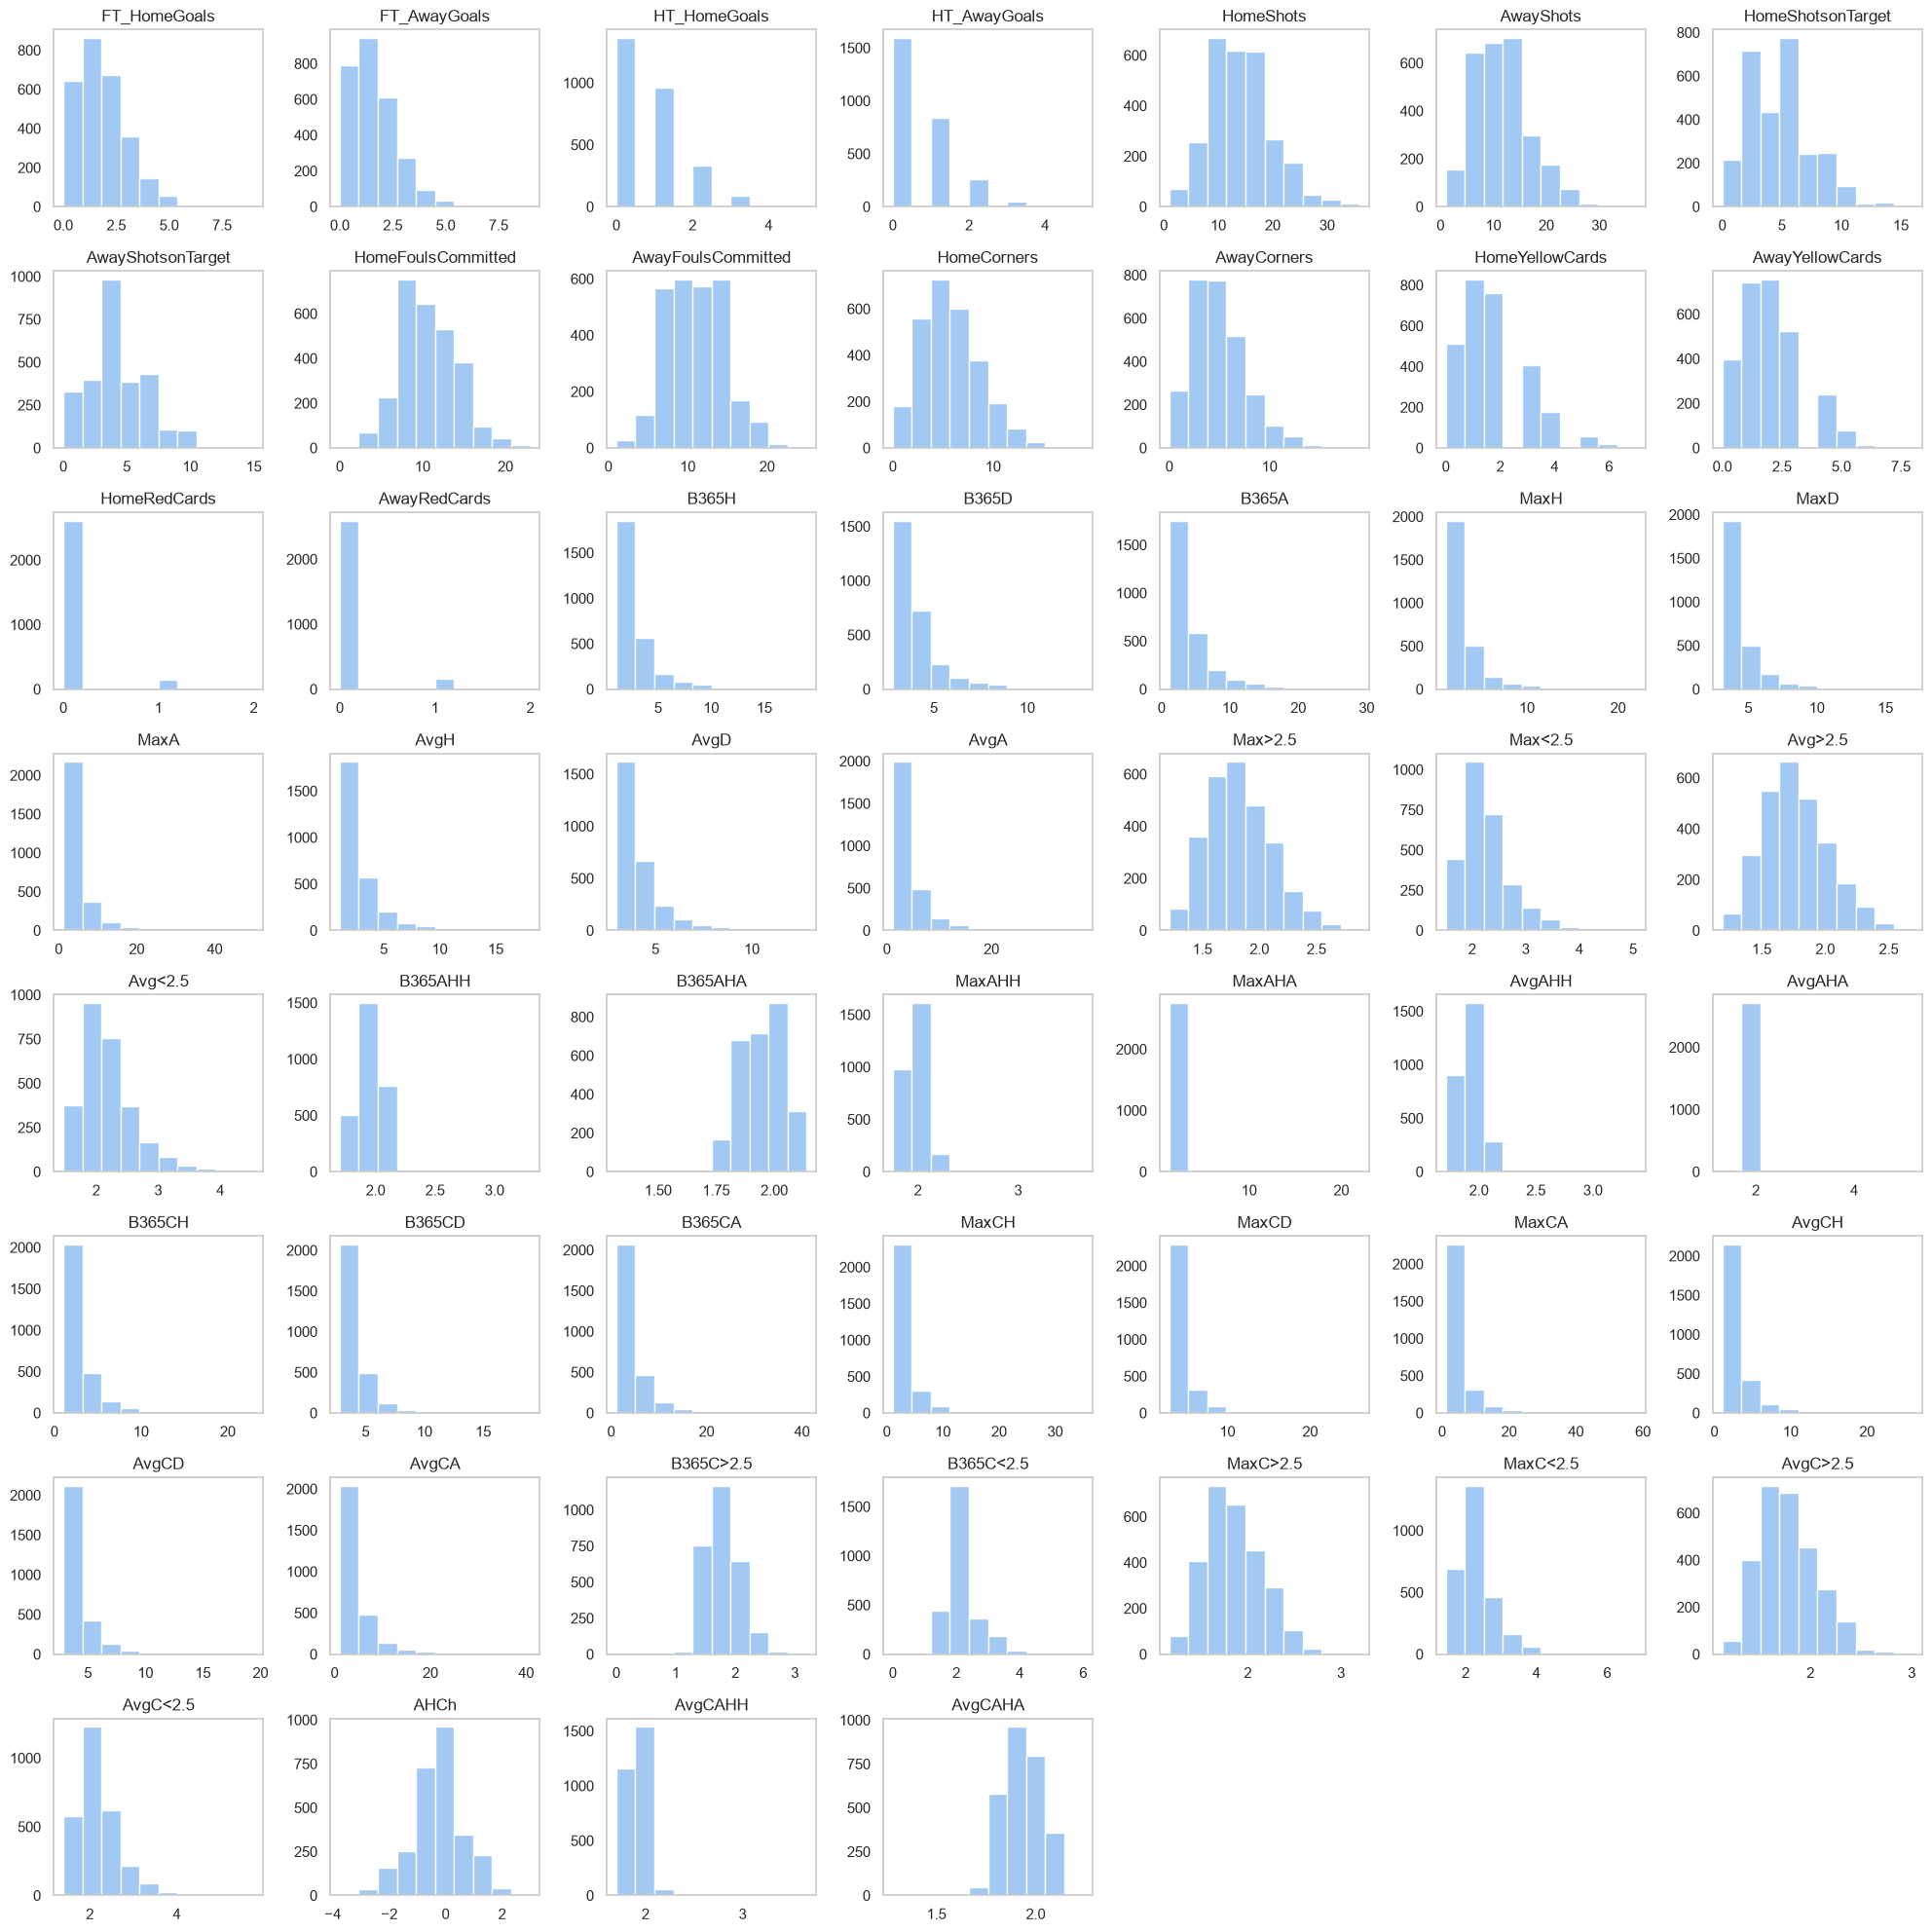

In [13]:
# visualise the distribution to see any outliers
df.hist(figsize=(20,20),grid=False);

plt.tight_layout()

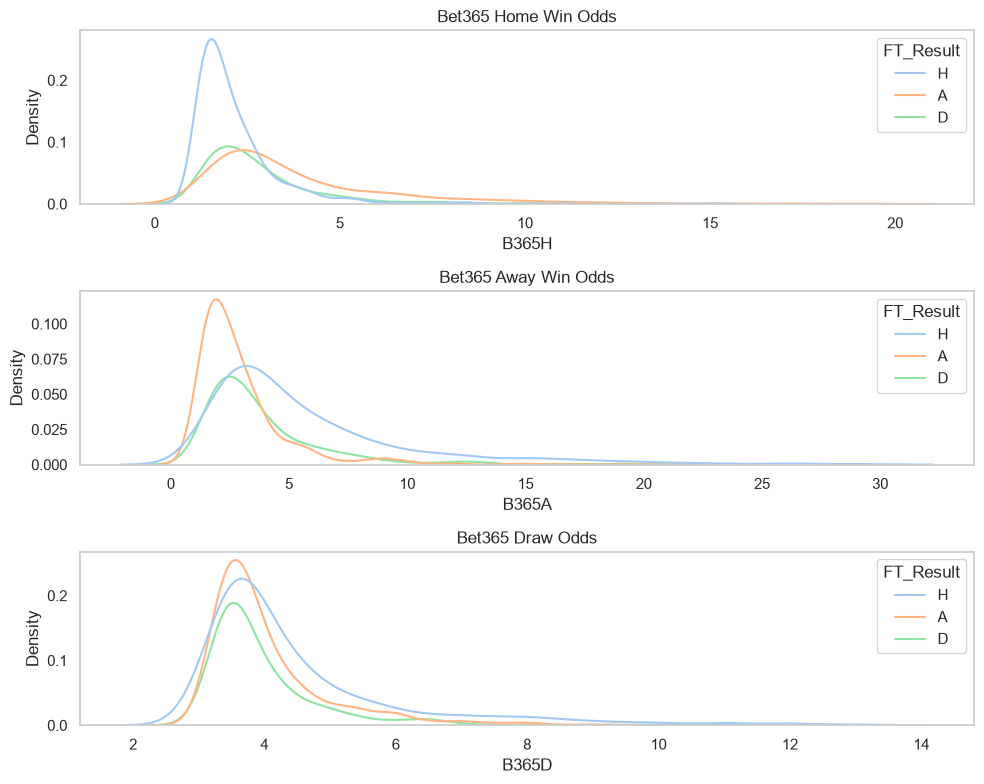

In [14]:
# The Bet365 features look to have extreme values.
# Lets investigate why this and validate if they are true outliers

bet365 = df[['B365H','B365D','B365A','FT_Result']].copy()

fig,axes = plt.subplots(3,1,figsize=(10,8))
sns.kdeplot(data=bet365,x='B365H',hue='FT_Result',ax=axes[0]);
sns.kdeplot(data=bet365,x='B365A',hue='FT_Result',ax=axes[1]);
sns.kdeplot(data=bet365,x='B365D',hue='FT_Result',ax=axes[2]);

axes[0].set_title('Bet365 Home Win Odds');
axes[1].set_title('Bet365 Away Win Odds');
axes[2].set_title('Bet365 Draw Odds');

# remove grid 
for ax in axes:
    ax.grid(False)
    
plt.tight_layout()

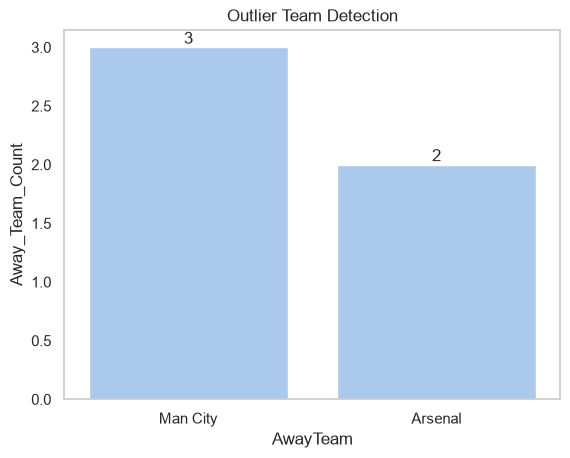

In [15]:
# filter out the extreme home win odds to see what those games were
outliers = (df['B365H'] > 15)

agg_df = (df[['HomeTeam','AwayTeam']]
            .loc[outliers]
            .groupby('AwayTeam')
            .agg(Away_Team_Count=('HomeTeam','count'))
            .reset_index()
            .sort_values('Away_Team_Count',ascending=False)
            )

ax = sns.barplot(data=agg_df,x='AwayTeam',y='Away_Team_Count');

for container in ax.containers:
    ax.bar_label(container)

plt.title('Outlier Team Detection')
plt.grid(False)
plt.show()

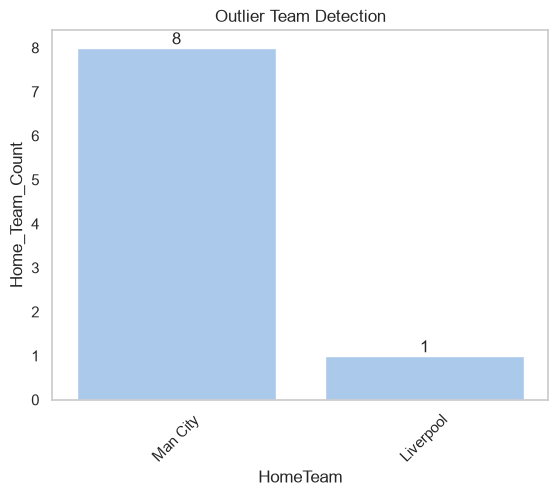

In [16]:
# filter out the extreme home win odds to see what those games were
outliers = (df['B365A'] > 25)

agg_df = (df[['HomeTeam','AwayTeam']]
            .loc[outliers]
            .groupby('HomeTeam')
            .agg(Home_Team_Count=('HomeTeam','count'))
            .reset_index()
            .sort_values('Home_Team_Count',ascending=False)
            )

ax = sns.barplot(data=agg_df,x='HomeTeam',y='Home_Team_Count');

for container in ax.containers:
    ax.bar_label(container)

for item in ax.get_xticklabels():
    item.set_rotation(45)

plt.title('Outlier Team Detection')
plt.grid(False)
plt.show()

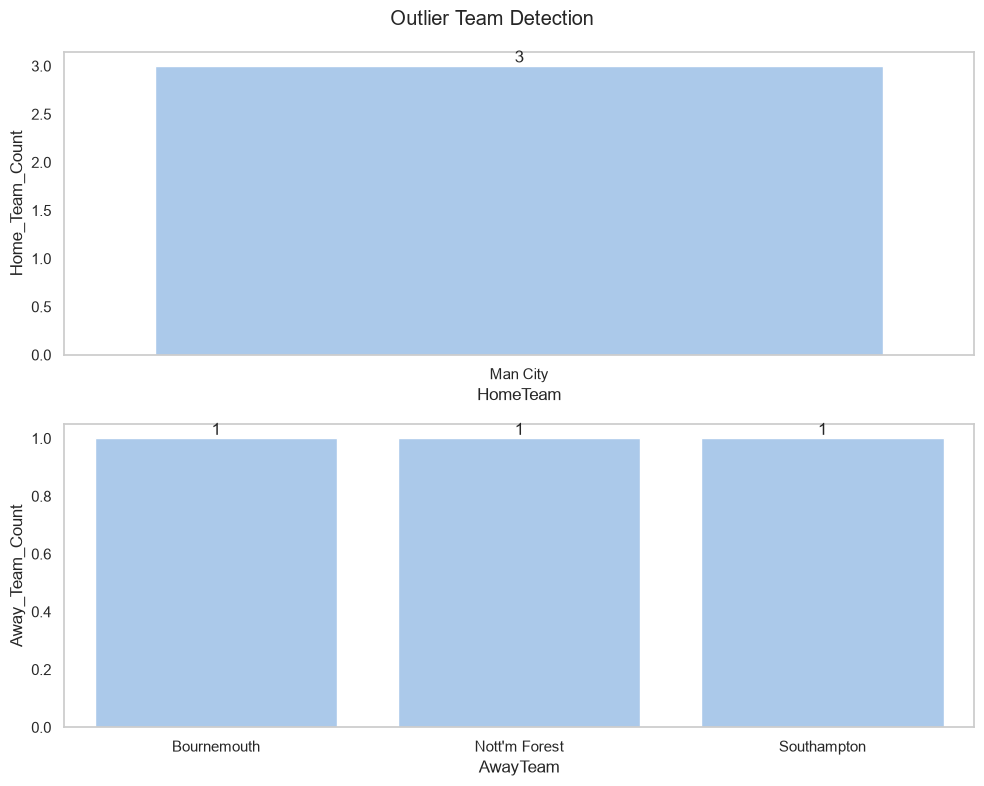

In [17]:
# filter out the extreme home win odds to see what those games were
outliers = (df['B365D'] > 12)

agg_df = (df[['HomeTeam','AwayTeam']]
            .loc[outliers]
            .groupby('HomeTeam')
            .agg(Home_Team_Count=('HomeTeam','count'))
            .reset_index()
            .sort_values('Home_Team_Count',ascending=False)
            )

agg_dfb = (df[['HomeTeam','AwayTeam']]
            .loc[outliers]
            .groupby('AwayTeam')
            .agg(Away_Team_Count=('HomeTeam','count'))
            .reset_index()
            .sort_values('Away_Team_Count',ascending=False)
            )

fig,axes = plt.subplots(2,1,figsize=(10,8))

ax = sns.barplot(data=agg_df,x='HomeTeam',y='Home_Team_Count',ax=axes[0]);
ax1 = sns.barplot(data=agg_dfb,x='AwayTeam',y='Away_Team_Count',ax=axes[1]);

bars = [ax,ax1]

for bar in bars:
  for container in bar.containers:
      bar.bar_label(container)


plt.suptitle('Outlier Team Detection')
for ax in axes:
   ax.grid(False)
plt.tight_layout()
plt.show()

**Observations**

Based on the observation in the above analysis, it appears that Bet365 favours higher ranked teams (teams that typically place in the top 4/5 in the league) over lower ranked teams. Therefore, these outliers are true datapoints and will remain in the dataset.

## Data Consistency

In [18]:
df.info()

<class 'pandas.DataFrame'>
Index: 2760 entries, 0 to 379
Data columns (total 62 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   League Division     2760 non-null   str    
 1   Date                2760 non-null   str    
 2   Time                2760 non-null   str    
 3   HomeTeam            2760 non-null   str    
 4   AwayTeam            2760 non-null   str    
 5   FT_HomeGoals        2760 non-null   int64  
 6   FT_AwayGoals        2760 non-null   int64  
 7   FT_Result           2760 non-null   str    
 8   HT_HomeGoals        2760 non-null   int64  
 9   HT_AwayGoals        2760 non-null   int64  
 10  HT_Result           2760 non-null   str    
 11  Match Referee       2760 non-null   str    
 12  HomeShots           2760 non-null   int64  
 13  AwayShots           2760 non-null   int64  
 14  HomeShotsonTarget   2760 non-null   int64  
 15  AwayShotsonTarget   2760 non-null   int64  
 16  HomeFoulsCommitted  276

In [19]:
# Drop league division as this analysis focuses on Premier League
df.drop(columns='League Division',inplace=True)

In [20]:
df.info()

<class 'pandas.DataFrame'>
Index: 2760 entries, 0 to 379
Data columns (total 61 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date                2760 non-null   str    
 1   Time                2760 non-null   str    
 2   HomeTeam            2760 non-null   str    
 3   AwayTeam            2760 non-null   str    
 4   FT_HomeGoals        2760 non-null   int64  
 5   FT_AwayGoals        2760 non-null   int64  
 6   FT_Result           2760 non-null   str    
 7   HT_HomeGoals        2760 non-null   int64  
 8   HT_AwayGoals        2760 non-null   int64  
 9   HT_Result           2760 non-null   str    
 10  Match Referee       2760 non-null   str    
 11  HomeShots           2760 non-null   int64  
 12  AwayShots           2760 non-null   int64  
 13  HomeShotsonTarget   2760 non-null   int64  
 14  AwayShotsonTarget   2760 non-null   int64  
 15  HomeFoulsCommitted  2760 non-null   int64  
 16  AwayFoulsCommitted  276

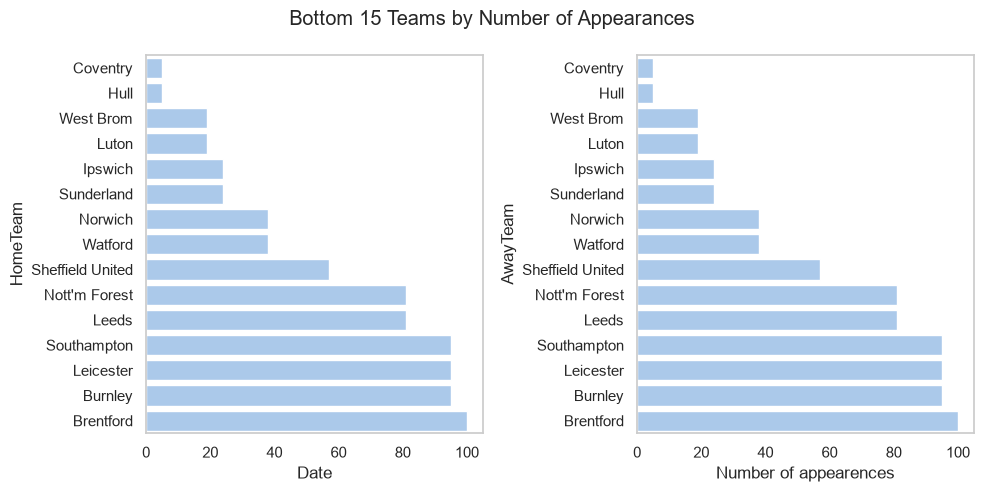

In [22]:
# Focus on the bottom 15 teams as these will be where inconsistent data entries lie.

# agg the data
hteams = (df.groupby('HomeTeam')['Date']
            .count()
            .reset_index()
            .sort_values(ascending=True,by='Date')
)
ateams = (df.groupby('AwayTeam')['Date']
            .count()
            .reset_index()
            .sort_values(ascending=True,by='Date')
)

# visualise
fig,axes = plt.subplots(1,2,figsize=(10,5))
sns.barplot(data=hteams.head(15),x='Date',y='HomeTeam',ax=axes[0]);
sns.barplot(data=ateams.head(15),x='Date',y='AwayTeam',ax=axes[1]);

# clean up the visuals
for ax in axes:
    ax.grid(False)
plt.xlabel('Number of appearences')
plt.suptitle('Bottom 15 Teams by Number of Appearances')
plt.tight_layout()

In [23]:
# there should only be 3 entrues for Full Time Result (H=Home Win, D=Draw, A=Away Win)

df['FT_Result'].value_counts().reset_index()

,FT_Result,count
0,H,1197
1,A,907
2,D,656


There are 45 different Referees in the dataset


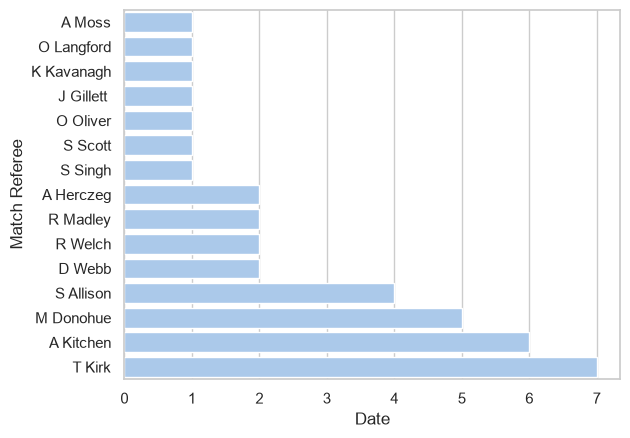

In [24]:
# now take the same approach as home and away teams with refs
# agg the data
refs = (df.groupby('Match Referee')['Date']
            .count()
            .reset_index()
            .sort_values(ascending=True,by='Date')
)

ref_Count = df['Match Referee'].nunique()

print(f'There are {ref_Count} different Referees in the dataset')
sns.barplot(data=refs.head(15),x='Date',y='Match Referee');

## Data Type

In [25]:
# set the match date a date data type

df['Date'].str.rfind('/')

# there were some errors in the date where the year was showing 06 instead of 2006.
# the below corrects this by finding the year with only 2 string values, then changing them to create the
# proper format.
df['Date'] = pd.to_datetime(
    df['Date'].apply(
    lambda x: x[:x.rfind('/')+1] + "20" + x[x.rfind('/')+1:]
    if len(x[x.rfind('/')+1:]) == 2 else x
))

In [26]:
# add in time series features
df['DayofWeek'] = df['Date'].dt.day_name()
df['Month'] = df['Date'].dt.month_name()
df['Year'] = df['Date'].dt.year

# add in season of the year
def season_of_yr(x):
  if x in ['December','January','February']:
    return 'Winter'
  elif x in ['March','April','May']:
    return 'Spring'
  elif x in ['June','July','August']:
    return 'Summer'
  else:
    return 'Autumn'

# create feature
df['SeasonOfYear'] = df['Month'].apply(season_of_yr)

In [27]:
df

,Date,Time,HomeTeam,AwayTeam,FT_HomeGoals,FT_AwayGoals,FT_Result,HT_HomeGoals,HT_AwayGoals,HT_Result,...,AvgC>2.5,AvgC<2.5,AHCh,AvgCAHH,AvgCAHA,Season,DayofWeek,Month,Year,SeasonOfYear
0,2026-08-21,20:00,Arsenal,Coventry,3,0,H,2,0,H,...,1.55,2.37,-2.00,2.02,1.74,2627,Friday,August,2026,Summer
1,2026-08-22,12:30,Hull,Man United,2,0,H,2,0,H,...,1.55,2.38,1.50,1.82,1.92,2627,Saturday,August,2026,Summer
2,2026-08-22,15:00,Everton,Crystal Palace,2,0,H,1,0,H,...,1.93,1.83,-0.25,1.96,1.79,2627,Saturday,August,2026,Summer
3,2026-08-22,15:00,Ipswich,Sunderland,2,1,H,1,1,D,...,2.14,1.67,0.00,1.99,1.77,2627,Saturday,August,2026,Summer
4,2026-08-22,15:00,Nott'm Forest,Leeds,0,1,A,0,0,D,...,2.12,1.69,-0.25,2.07,1.70,2627,Saturday,August,2026,Summer
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
375,2020-07-26,16:00,Leicester,Man United,0,2,A,0,0,D,...,1.80,2.03,0.50,1.86,2.02,1920,Sunday,July,2020,Summer
376,2020-07-26,16:00,Man City,Norwich,5,0,H,2,0,H,...,1.13,5.77,-3.75,2.02,1.84,1920,Sunday,July,2020,Summer
377,2020-07-26,16:00,Newcastle,Liverpool,1,3,A,1,1,D,...,1.57,2.40,1.00,1.95,1.92,1920,Sunday,July,2020,Summer
378,2020-07-26,16:00,Southampton,Sheffield United,3,1,H,0,1,A,...,1.82,2.01,-0.50,1.98,1.89,1920,Sunday,July,2020,Summer


# EDA

## Functions for EDA

### Visuals

In [588]:
# create a function that adjust visual axis
def adjust_visuals(title:str, x_label:str, y_label:str ,ax_obj=None):
  # create reuable title and label adjsutments dict
  title_params = {
        'fontsize':18,
        'fontweight':'bold',
        'color':'grey'
    }

  axis_params = {
        'fontsize':12,
        'fontweight':'bold',
        'color':'grey'
    }

  # we may encounter the use of subplots.
  # the below controls for this
  if not ax_obj is None:
    adjust_visual_obj(ax_obj,title,x_label,y_label,title_params,axis_params)
  else:
    # adjust the labels
    plt.xlabel(
        x_label,
        **axis_params
        );
    plt.ylabel(
        y_label,
        **axis_params
        );

    plt.title(
        title,
        **title_params
        );

    plt.grid(
        linestyle='--',
        alpha=0.25
    )
  # outside loop
  plt.tight_layout()





def adjust_visual_obj(ax_obj,title,x_label,y_label,title_params,axis_params):
  plt.suptitle(
      title,
      **title_params
      );

  # loop thorugh object and adjust
  for ax in ax_obj:
    ax.set_xlabel(
        x_label,
        **axis_params
        );
    ax.set_ylabel(
        y_label,
        **axis_params
    )
    ax.grid(
        linestyle='--',
        alpha=0.25
    )





In [589]:
def add_matrix_colour(df,title=None):
  cm = sns.light_palette("green", as_cmap=True)
  styled = (
      df.style
      .background_gradient(cmap=cm)
      .set_table_styles([
            {'selector': 'th', 'props': [
                ('background-color', '#1B2A4A'),
                ('color', 'white'),
                ('font-weight', 'bold')
            ]}
        ])
  )
  if title:
    styled = styled.set_caption(title)
  return styled

In [590]:
def show_the_relartionship(df,**kwargs):

  #extract argss
  var1 = kwargs.get('var1')
  var2 = kwargs.get('var2')
  result = kwargs.get('result')
  plot_kind = kwargs.get('kind')
  title = kwargs.get('title')
  x_label_ = kwargs.get('x_label')
  y_label_ = kwargs.get('y_label')

  # show the distribution and relationships
  corr_tb = df[[var1,var2]].corr()
  corr_tb = corr_tb.round(2)
  print(f"Goals For & Against Correlation: \n\n {corr_tb}\n\n")

  plt.figure(
      figsize=(10,8)
  );

  sns.jointplot(
      data=df,
      x=var1,
      y=var2,
      hue=result,
      kind=plot_kind
    );


  # format the plot
  adjust_visuals(
      title=title,
      x_label=x_label_,
      y_label=y_label_
  );

In [591]:
def calculate_win_pct(df: pd.DataFrame,team: str) -> pd.DataFrame:
  df = df.copy()
  sort_by_arg = 'H' if team == 'HomeTeam' else 'A'

  # run the pivot
  Wins = (
    df.pivot_table(
    index=team,
    columns='FT_Result',
    values='League Division',
    aggfunc='count'
  )
  .sort_values(by=sort_by_arg,ascending=False)
  .reset_index()
  )

  # calculate the proportions
  Wins['H_pct'] = Wins['H']/Wins.select_dtypes(exclude='object').sum(axis=1)
  Wins['D_pct'] = Wins['D']/Wins.select_dtypes(exclude='object').sum(axis=1)
  Wins['A_pct'] = Wins['A']/Wins.select_dtypes(exclude='object').sum(axis=1)

  # drop counts
  Wins.drop(columns=['H','D','A'],inplace=True)

  # Show the matrix
  return add_matrix_colour(Wins,title=f"{team} Win Proportions")

### Chi2

In [592]:
def contingency_table_(col1,target,title=None,col2=None):
  # create contingency table
  if col2 is not None:
    ct = pd.crosstab(
        [col1,col2],
        target
    )
  else:
    ct = pd.crosstab(
        col1,
        target
    )

  # adjust the table using add_matrix_colour
  return add_matrix_colour(ct,title=title)

In [593]:
def conduct_chi2(ct_observed, confidence):
  """
  This function is to simply re-use chi2 test as we are dealing
  with numerous counts for each feature.
  """
  # calculate the stats
  chi2, p, DoF, expected_value = chi2_contingency(ct_observed)

  # use if function to test whether the p surpasses confidence
  # to allow for rejecting of Null
  if p <= confidence:
    print("Reject Null Hypothesis -> There is evidence that the features are dependent")
  else:
    print("Fail to Reject Null Hypothesis")

  # print the stats
  print("*"*50)
  print(f"Chi2 Value: {chi2:.2f}")
  print(f"P-Value: {p:.2f}")
  print(f"Degrees of Freedom: {DoF}")
  print(f"Expected Value: \n{expected_value}")
  print("*"*50)


In [594]:
def run_chi2_test(**kwargs):
  #extract the inputs
  var1 = kwargs.get('var1')
  target = kwargs.get('target')
  confidence = kwargs.get('confidence')

  home_goals_ct = pd.crosstab(
        var1,
        target
    )
  # show the table
  tbl = contingency_table_(
        var1,
        target=target
    )

  # perform chi2 test
  conduct_chi2(home_goals_ct,confidence=confidence)



  return tbl

### Probability

In [595]:
class ProbabilityModelling:
  def __init__(self, df: pd.DataFrame,  outcome: str, n_trials: int = 19):
    self.df = df
    self.outcome = outcome
    self.nTrials = n_trials
    self.x = np.arange(0,self.nTrials+1)

    # Explicit attribute initialization
    self.pTbl: pd.DataFrame | None = None
    self.pH: float = 0.0
    self.dist: np.ndarray | None = None
    self.bayes_dist: np.ndarray | None = None
    self.cmf: np.ndarray | None = None
    self.mean: float = 0.0
    self.var: float = 0.0
    self.std: float = 0.0
    self.n: int = 0

  def data_prep(self, method_of_prep : str = "frequentist") -> None:

    # check which method to use count or proportions
    if method_of_prep == "frequentist":
      proportion_or_count = True
      col = 'proportion'
    elif method_of_prep == "bayesian":
      proportion_or_count = False
      col = 'count'
    else:
      raise ValueError("Invalid method_of_prep. Please choose 'frequentist' or 'bayesian'.")
      # calculate the proportions
    self.pTbl = self.df['FT_Result'].value_counts(normalize=proportion_or_count).reset_index()

    # take sample size
    self.n = self.pTbl[col].sum()
    # get target outcome
    self.pH = (
          self.pTbl
          .loc[self.pTbl['FT_Result']==self.outcome][col]
          .item()
          )

  def calculate_global_prior(self, all_data, team_status):
    """
    I want to calculate global prior for teams with little info - newly promoted
    this function will do just that by grouping and extracting the count of wins
    the newly promoted teams get.
    """
    if all_data is None or all_data.empty:
        raise ValueError("unfiltered_data/all_data must be provided for informative priors.")

    # use all the train dataset got global prior
    mask = all_data['HomeTeamLeagueStatus'] == team_status
    globalTbl = (
        all_data['FT_Result']
            .loc[mask]
            .value_counts()
            .reset_index()
         )

    globalAlpha = (
          globalTbl
          .loc[globalTbl['FT_Result']==self.outcome]['count']
          .item()
          )
    globalBeta = globalTbl['count'].sum() - globalAlpha

    self.globalPrior = [globalAlpha,globalBeta]

    return self.globalPrior


  def binomial_modelling(self) -> None:

    # create the distribution
    self.dist = binom.pmf(self.x,self.nTrials,self.pH)
    self.cmf = binom.cdf(self.x,self.nTrials,self.pH)
    # obtain distribution stdev and mean
    self.mean, self.var = binom.stats(self.nTrials, self.pH, moments='mv')
    self.std = np.sqrt(self.var)

  def geometric_modelling(self) -> None:

    # create the distribution
    self.dist = geom.pmf(self.x,self.pH)
    self.cmf = geom.cdf(self.x,self.pH)

    # obtain distribution stdev and mean
    self.mean, self.var = geom.stats(self.pH, moments='mv')
    self.std = np.sqrt(self.var)

  def beta_modelling(self, prior : str, unfiltered_data : pd.DataFrame = None, team_status:str = None) -> None:

    prior_arr = [1,1] if prior == 'uninformative' else self.calculate_global_prior(unfiltered_data,team_status)
    alpha = self.pH + prior_arr[0]
    beta_ = (self.n-self.pH) + prior_arr[1]
    # create the distribution
    self.bayes_dist = beta.pdf(np.linspace(0,1,500),alpha,beta_)

    # get the stats (update pH with beta mean)
    self.pH, self.varBetaDist = beta.stats(alpha,beta_,moments='mv')
    self.stdBetaDist = np.sqrt(self.varBetaDist)


  def show_distribution(self, bayesian_method : bool = False) -> None:
    fig, axes = plt.subplots(
        2,1,figsize=(10,6)
    )

    if not bayesian_method:
      # show results
      sns.barplot(
            x=self.x,
            y=self.dist,
            label=f'n={self.nTrials}, p={self.pH*100:.2f}, mu={self.mean:.0f}, stdev={self.std:.0f}',
            ax=axes[0]
      )

      sns.lineplot(
            x=self.x,
            y=self.cmf,
            ax=axes[1]
      )
    else:
      # show results
      sns.barplot(
            x=self.x,
            y=self.dist,
            label=f'n={self.nTrials}, p={self.pH*100:.2f}, mu={19*self.pH:.0f}, stdev={self.std:.0f}',
            ax=axes[0]
      )

      sns.lineplot(
            x=np.linspace(0,1,500),
            y=self.bayes_dist,
            label=f'n={self.nTrials}, p={self.pH*100:.2f}, mu={19*self.pH:.0f}, stdev={self.stdBetaDist*100:.3f}',
            ax=axes[1]
      )

    # Attach legend explicitly to both subplots
    axes[0].legend()
    axes[1].legend()

    # adjust the visual
    if "adjust_visuals" in globals():
      adjust_visuals(
          title="Probability Mass Function (19-Match Horizon)",
          x_label="Number of Outcomes",
          y_label="Probability",
          ax_obj=axes
      )
  def run_model(self, **kwargs):
    model_type = kwargs.get('model_type')
    prior = kwargs.get('prior')
    data_prep_method = kwargs.get('method_of_prep')
    team_status = kwargs.get('team_status')

    all_data = kwargs.get('all_data')


    # run data prep
    self.data_prep(method_of_prep=data_prep_method)
    if model_type=='binomial':
      self.binomial_modelling()
      self.show_distribution()
    elif model_type=='geometric':
      self.geometric_modelling()
      self.show_distribution()
    elif model_type=='beta-binomial':
      self.beta_modelling(prior=prior, unfiltered_data=all_data, team_status=team_status)
      self.binomial_modelling()
      self.show_distribution(bayesian_method=True)
    else:
      raise ValueError("Invalid model_type. Please choose 'binomial', 'geometric' or beta-binomial.")



### Feature Engineering

#### Lagged Shots

In [596]:
def lagged_shots_feature(df:pd.DataFrame, team:str, shotsOT:str) -> pd.DataFrame:

  df = df.copy()

  df[f'{team}5MatchShotsOTMean'] = df.groupby(team)[shotsOT].transform(
      lambda x: x.shift(1).rolling(5, min_periods=1).mean()
      ).fillna(0)

  # control for conceded shots OT.
  # we are asking - how many shots OT did the home team leak?
  if team == 'HomeTeam':
    concededTeam = 'AwayShotsonTarget'
  else:
    concededTeam = 'HomeShotsonTarget'

  df[f'{team}5MatchShotsOTConcededMean'] = df.groupby(team)[concededTeam].transform(
      lambda x: x.shift(1).rolling(5, min_periods=1).mean()
      ).fillna(0)


  # place the feature into a bucket
  def new_bucket(shots):
    if shots >= 6:
      return '6+'
    elif shots >= 3:
      return '3-5'
    else:
      return '0-2'

  df[f'{team}5MatchShotsOTMeanBucket'] = df[f'{team}5MatchShotsOTMean'].apply(new_bucket)
  df[f'{team}5MatchShotsOTConcededMeanBucket'] = df[f'{team}5MatchShotsOTConcededMean'].apply(new_bucket)

  return df

In [597]:
def lagged_shots_feature_nOT(df:pd.DataFrame, team:str, shotsOT:str) -> pd.DataFrame:

  df = df.copy()

  df[f'{team}5MatchShotsMean'] = df.groupby(team)[shotsOT].transform(
      lambda x: x.shift(1).rolling(5, min_periods=1).mean()
      ).fillna(0)

  # control for conceded shots OT.
  # we are asking - how many shots OT did the home team leak?
  if team == 'HomeTeam':
    concededTeam = 'AwayShots'
  else:
    concededTeam = 'HomeShots'

  df[f'{team}5MatchShotsConcededMean'] = df.groupby(team)[concededTeam].transform(
      lambda x: x.shift(1).rolling(5, min_periods=1).mean()
      ).fillna(0)

  def new_bucket_shots(shots):
    if shots >= 15:
        return '15+'
    elif shots >= 8:
        return '8-14'
    else:
        return '0-7'

  df[f'{team}5MatchShotsMeanBucket'] = df[f'{team}5MatchShotsMean'].apply(new_bucket_shots)
  df[f'{team}5MatchShotsConcededMeanBucket'] = df[f'{team}5MatchShotsConcededMean'].apply(new_bucket_shots)

  return df

#### Lagged Goals

In [598]:
"""
Let us see how the avg goals for and against the team interacs with the match outcome.
To do this, I will create a rolling avg of goals scored and conceded by team - lagged by 1, 3 and 5 games.
The reason for this is to show both long and short term performance of the given team as I want to answer the following questions:

1. does the previous home / away team goals conceded influence the next match outcome?
ie does a team that concede 5 goals bounce back in their next home/away game or does the rotten performance continue?
2. do medium to long-term rolling avg of goals scored and conceded influence the next match outcome?
ie if a team has a high avg ie 4 goals per game, does that confidence flow into the next game?

"""

def rolling_goals_for_and_against(df:pd.DataFrame):
  df = df.copy()
  # ===============
  # last game
  # ===============

  # home team
  df['HomeTeamLastGameGoalsConceded'] = df.groupby('HomeTeam')['FT_AwayGoals'].transform(
      lambda x: x.shift(1)
  ).fillna(0)

  df['HomeTeamLastGameGoalsScored'] = df.groupby('HomeTeam')['FT_HomeGoals'].transform(
      lambda x: x.shift(1)
  ).fillna(0)


  #away team
  df['AwayTeamLastGameGoalsConceded'] = df.groupby('AwayTeam')['FT_HomeGoals'].transform(
      lambda x: x.shift(1)
  ).fillna(0)

  df['AwayTeamLastGameGoalsScored'] = df.groupby('AwayTeam')['FT_AwayGoals'].transform(
      lambda x: x.shift(1)
  ).fillna(0)
  # ===============
  # last 3-5 games
  # ===============
  df = rolling_goals_for_last_n_games(df)

  #return result
  return df


def rolling_goals_for_last_n_games(df:pd.DataFrame):

  for i in [3,5]:
    # home team
    df[f'HomeTeamLast{i}GamesGoalsConcededAvg'] = df.groupby('HomeTeam')['FT_AwayGoals'].transform(
        lambda x: x.shift(1).rolling(window=i,min_periods=1).mean()
    ).fillna(0)

    df[f'HomeTeamLast{i}GamesGoalsScoredAvg'] = df.groupby('HomeTeam')['FT_HomeGoals'].transform(
        lambda x: x.shift(1).rolling(window=i,min_periods=1).mean()
    ).fillna(0)

    #away team
    df[f'AwayTeamLast{i}GamesGoalsConcededAvg'] = df.groupby('AwayTeam')['FT_HomeGoals'].transform(
        lambda x: x.shift(1).rolling(window=i,min_periods=1).mean()
    ).fillna(0)

    df[f'AwayTeamLast{i}GamesGoalsScoredAvg'] = df.groupby('AwayTeam')['FT_AwayGoals'].transform(
        lambda x: x.shift(1).rolling(window=i,min_periods=1).mean()
    ).fillna(0)

  return df




In [599]:
"""
I will add this feature into my train and test set either way as a ML model may pick up
interactions with other features, ie team, that I was unable to see.
For example, the interaction between home team being a Top 6 team vs a bottom 6 away team.
"""
def shot_acc_feature(df):
  df = df.copy()

  # create the features for lagged 5 games
  df = lagged_shots_feature_nOT(df,'HomeTeam','HomeShots')
  df = lagged_shots_feature_nOT(df,'AwayTeam','AwayShots')

  df['HomeTeam5MatchMeanShotAccConceded'] = (df['HomeTeam5MatchShotsOTConcededMean']/df['HomeTeam5MatchShotsConcededMean']).fillna(0)
  df['AwayTeam5MatchMeanShotAccConceded'] = (df['AwayTeam5MatchShotsOTConcededMean']/df['AwayTeam5MatchShotsConcededMean']).fillna(0)

  return df

#### Lagged Match Outcome

In [600]:
"""
lets create a rolling win, draw and loss percentage for each home and away team
as it shows key insights for our ML model to make good predictions as it will provide
signal as to which team (home or away) is likely to win given their histroic home/away performance.
"""

def rolling_win_pct(df:pd.DataFrame, team:str) -> pd.DataFrame:
  df = df.copy()

  # sort df in asc order
  df.sort_index(inplace=True)

  # create helper col that detrmines home wins
  df['HomeWin'] = df.apply(lambda x: 1 if x['FT_Result'] == 'H' else 0, axis=1)
  df['AwayWin'] = df.apply(lambda x: 1 if x['FT_Result'] == 'A' else 0, axis=1)
  df['Draw'] = df.apply(lambda x: 1 if x['FT_Result'] == 'D' else 0, axis=1)

  # loop through the outcomes to calculate the roling win,loss and draw pct by team.
  outcome_list = ['HomeWin','AwayWin','Draw']
  for outcome in outcome_list:
    df[f'{team}{outcome}Pct'] = (
        df.groupby(team)[outcome].transform(
            lambda x: x.shift(1).expanding().sum()
            )/
        df.groupby(team)[outcome].transform(
            lambda x: x.shift(1).expanding().count()
            )
    ).fillna(0)

  # drop the helper columns
  df.drop(columns=['HomeWin','AwayWin','Draw'],inplace=True)

  return df

## Data Split

In [28]:
df['Season'].unique()

<StringArray>
['2627', '2526', '2425', '2324', '2223', '2122', '2021', '1920']
Length: 8, dtype: str

In [29]:
# create train and test set.
# I am going to use the latest season as test set as I want to see how previous seasons
# help the model to predict latest season results

# we wont drop the target for now as will need it to create lagged features - Time Series!!
x_train, x_val, x_test = (
    df.loc[df['Season'].isin(['2324', '2223', '2122', '2021', '1920', '1819'])].copy(),
    df.loc[df['Season'].isin(['2425'])].copy(),
    df.loc[df['Season'].isin(['2526'])].copy()
)

y_train, y_val, y_test = (
    df['FT_Result'].loc[df['Season'].isin(['2324', '2223', '2122', '2021', '1920', '1819'])].copy(),
    df['FT_Result'].loc[df['Season'].isin(['2425'])].copy(),
    df['FT_Result'].loc[df['Season'].isin(['2526'])].copy()
)

# create df for EDA
train_df = df.loc[df['Season'].isin(['2324', '2223', '2122', '2021', '1920', '1819'])].copy()

## The basics

### Home And Away Stats

In [603]:
# Who has the best home performance?
calculate_win_pct(df=train_df,team='HomeTeam')

FT_Result,HomeTeam,H_pct,D_pct,A_pct
0,Man City,0.807018,0.104523,0.087023
1,Liverpool,0.771930,0.156833,0.069608
2,Arsenal,0.649123,0.174445,0.174180
3,Tottenham,0.631579,0.087236,0.278943
4,Man United,0.561404,0.244410,0.191628
5,Chelsea,0.508772,0.288188,0.200354
6,Newcastle,0.447368,0.262129,0.287683
7,Wolves,0.429825,0.209736,0.357643
8,West Ham,0.429825,0.253430,0.313908
9,Everton,0.412281,0.209768,0.375146


In [604]:
# who has the best away performance?
calculate_win_pct(df=train_df,team='AwayTeam')

FT_Result,AwayTeam,H_pct,D_pct,A_pct
0,Man City,0.175439,0.140135,0.682322
1,Liverpool,0.175439,0.253995,0.568036
2,Arsenal,0.324561,0.192435,0.480278
3,Chelsea,0.342105,0.201151,0.453977
4,Man United,0.324561,0.227423,0.445213
5,Tottenham,0.359649,0.244842,0.392655
6,West Ham,0.508772,0.174659,0.313908
7,Newcastle,0.447368,0.253392,0.296423
8,Wolves,0.456140,0.253372,0.287683
9,Leicester,0.421053,0.230557,0.345002


**Notes**

1. You have the "Big 6" Teams in the top end of the matrix showing their superioirty in the league within this sampled dataset.
2. You can also see the newer teams that enter the league who appear to struggle to stay up due to poor win rates at home and away, showing the big gap between Championship and Premier League Football!

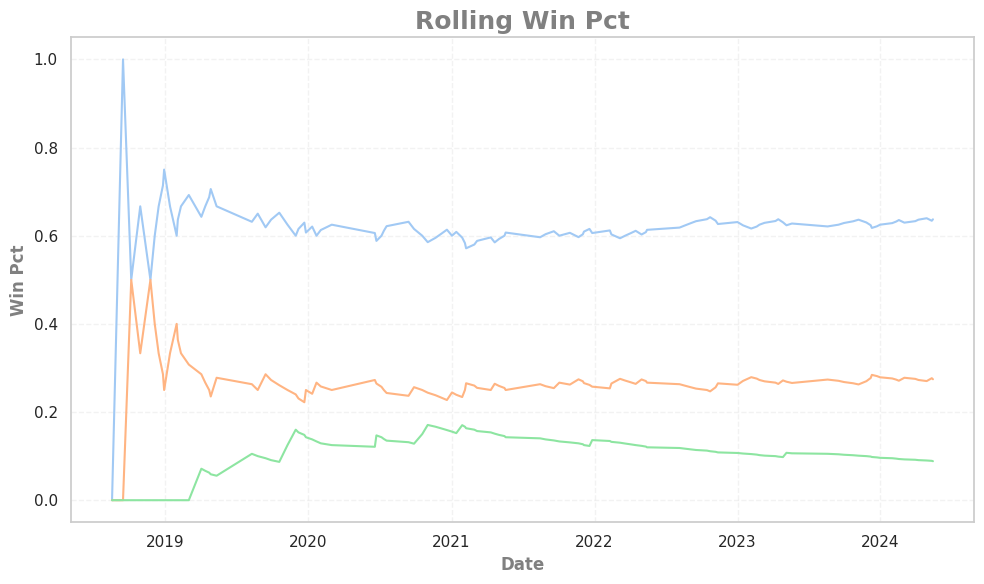

In [605]:
testing_df = rolling_win_pct(train_df,'HomeTeam')

tot_df = testing_df.loc[testing_df['HomeTeam']=='Tottenham']

# verify the results
plt.figure(
    figsize=(10,6)
)
sns.lineplot(
    data=tot_df,
    x=tot_df.index,
    y='HomeTeamHomeWinPct'
)

sns.lineplot(
    data=tot_df,
    x=tot_df.index,
    y='HomeTeamAwayWinPct'
)

sns.lineplot(
    data=tot_df,
    x=tot_df.index,
    y='HomeTeamDrawPct'
)

# adjsut visuals
adjust_visuals(
    title="Rolling Win Pct",
    x_label="Date",
    y_label="Win Pct"
)

In [606]:
# apply the logic to train, validate and test
train_df = rolling_win_pct(train_df,'HomeTeam')
train_df = rolling_win_pct(train_df,'AwayTeam')

x_train = rolling_win_pct(x_train,'HomeTeam')
x_train = rolling_win_pct(x_train,'AwayTeam')

x_val = rolling_win_pct(x_val,'HomeTeam')
x_val = rolling_win_pct(x_val,'AwayTeam')

x_test = rolling_win_pct(x_test,'HomeTeam')
x_test = rolling_win_pct(x_test,'AwayTeam')

In [607]:
x_train.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2280 entries, 2018-08-10 to 2024-05-19
Data columns (total 36 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   League Division     2280 non-null   object 
 1   HomeTeam            2280 non-null   object 
 2   AwayTeam            2280 non-null   object 
 3   FT_HomeGoals        2280 non-null   int64  
 4   FT_AwayGoals        2280 non-null   int64  
 5   FT_Result           2280 non-null   object 
 6   HT_HomeGoals        2280 non-null   int64  
 7   HT_AwayGoals        2280 non-null   int64  
 8   HT_Result           2280 non-null   object 
 9   Match Referee       2280 non-null   object 
 10  HomeShots           2280 non-null   int64  
 11  AwayShots           2280 non-null   int64  
 12  HomeShotsonTarget   2280 non-null   int64  
 13  AwayShotsonTarget   2280 non-null   int64  
 14  HomeFoulsCommitted  2280 non-null   int64  
 15  AwayFoulsCommitted  2280 non-null   i

### Match Outcome

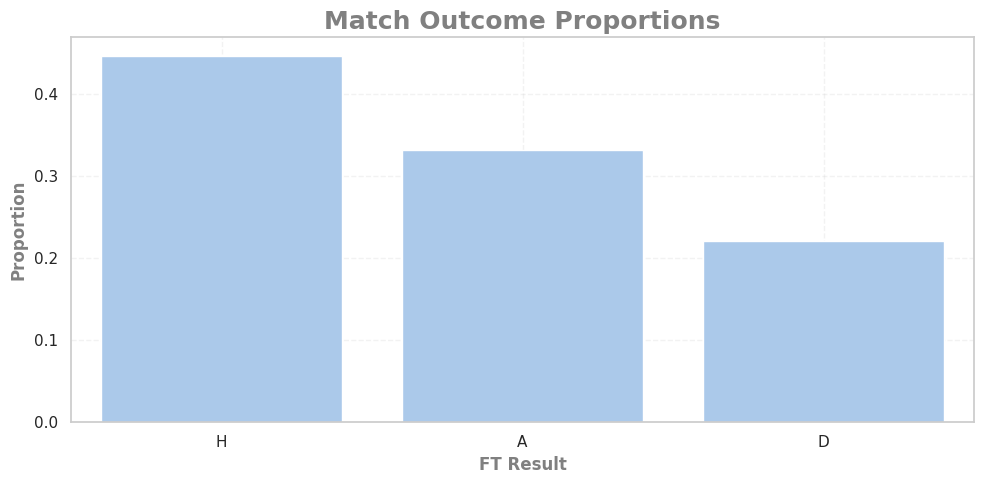

In [608]:
# WHat are the proportions of home win, Draw and Away Win?
p = (
    train_df['FT_Result']
    .value_counts(normalize=True)
    .reset_index()
)

# visualise the results
plt.figure(
    figsize=(10,5)
)

sns.barplot(
    data=p,
    x='FT_Result',
    y='proportion'
);

adjust_visuals(
    title="Match Outcome Proportions",
    x_label="FT Result",
    y_label="Proportion"
    )

**Notes**

1. Draws are the miority class.
2. Home wins are majority class -> Home advantage!
3. Away wins is not too far behind!
4. Home wins are going to be easier to predict due to being the dominant class while Draws will be difficult -> Minority class

### Match Shots

In [609]:
# review shot data at a glance
train_df[['HomeShots','AwayShots','HomeShotsonTarget','AwayShotsonTarget']].describe()


,HomeShots,AwayShots,HomeShotsonTarget,AwayShotsonTarget
count,2280.000000,2280.000000,2280.000000,2280.000000
mean,13.912719,11.522807,4.817105,4.079386
std,5.771411,5.105247,2.646724,2.404712
min,0.000000,1.000000,0.000000,0.000000
25%,10.000000,8.000000,3.000000,2.000000
50%,13.000000,11.000000,5.000000,4.000000
75%,17.000000,15.000000,6.000000,5.000000
max,36.000000,31.000000,15.000000,15.000000


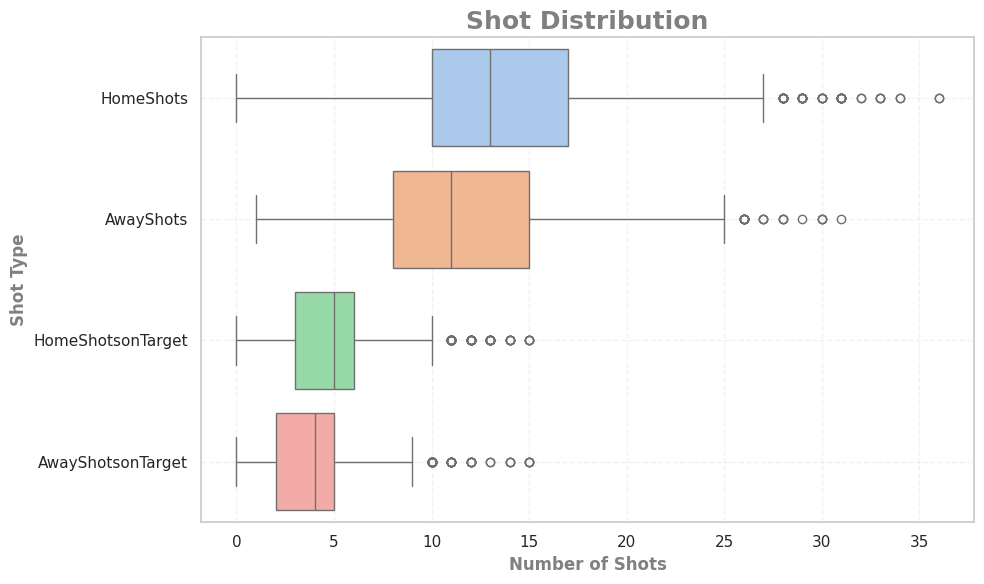

In [610]:
# show the distributions
plt.figure(
    figsize=(10,6)
)
sns.boxplot(
    data=train_df[['HomeShots','AwayShots','HomeShotsonTarget','AwayShotsonTarget']],
    orient='h'
)

adjust_visuals(
    title="Shot Distribution",
    x_label="Number of Shots",
    y_label="Shot Type"
)

In [611]:
# lets group by the result to see what happens to shots on target data
train_df[['HomeShotsonTarget','AwayShotsonTarget','FT_Result']].groupby('FT_Result').describe()

HomeShotsonTarget                                                \
                      count      mean       std  min  25%  50%  75%   max   
FT_Result                                                                   
A                     758.0  3.459103  2.133656  0.0  2.0  3.0  5.0  11.0   
D                     503.0  4.375746  2.285405  0.0  3.0  4.0  6.0  15.0   
H                    1019.0  6.045142  2.596643  0.0  4.0  6.0  8.0  15.0   

          AwayShotsonTarget                                                
                      count      mean       std  min  25%  50%  75%   max  
FT_Result                                                                  
A                     758.0  5.546174  2.488516  1.0  4.0  5.0  7.0  15.0  
D                     503.0  3.880716  2.085256  0.0  2.0  4.0  5.0  11.0  
H                    1019.0  3.086359  1.894154  0.0  2.0  3.0  4.0  10.0

In [612]:
# create a contringency table of the total count of shots on target by ft result
contingency_table = (
    train_df[['HomeShotsonTarget','AwayShotsonTarget','FT_Result']]
    .groupby('FT_Result')
    .sum()
    .reset_index()
)

add_matrix_colour(contingency_table,title="Contingency Table for total shots on target")



,FT_Result,HomeShotsonTarget,AwayShotsonTarget
0,A,2622,4204
1,D,2201,1952
2,H,6160,3145


#### Shots On Target

In [613]:
def bucket_shots_OT(shots):
    if shots >= 8:
        return '8+'
    elif shots >= 4:
        return '4-7'
    else:
        return '0-3'

train_df['HomeShotsOTBucket'] = train_df['HomeShotsonTarget'].apply(bucket_shots_OT)
train_df['AwayShotsOTBucket'] = train_df['AwayShotsonTarget'].apply(bucket_shots_OT)



# create a contringecy table
contingency_table_(
    col1=train_df['HomeShotsOTBucket'],
    target=train_df['FT_Result'],
    title="Contingency Table for Homeshots on target"
)



FT_Result,A,D,H
HomeShotsOTBucket,,,
0-3,415,191,170
4-7,312,269,583
8+,31,43,266


In [614]:
# create a contringecy table for away shots
# create a contringecy table
contingency_table_(
    col1=train_df['AwayShotsOTBucket'],
    target=train_df['FT_Result'],
    title="Contingency Table for Away shots on target"
)

FT_Result,A,D,H
AwayShotsOTBucket,,,
0-3,166,240,640
4-7,442,231,352
8+,150,32,27


In [615]:
# do we observe simpson paradox when we introduce homeshots
# create a contringecy table
contingency_table_(
    col1=train_df['HomeShotsOTBucket'],
    target=train_df['FT_Result'],
    title="Contingency Table for Home and Away shots on target",
    col2=train_df['AwayShotsOTBucket']
)

**Notes**

1. It appears that the more shots on target generally leads to a victory for the team - however, I must conduct CHi2 test to confirm this.
2. A draw tends to happen when the shots on target a relatively equal for both sides.
3. This feature is a great proxy for how well a team a team performs, as we do not have access to xG.

In [616]:
"""
====================================
My test:
====================================

h0: There is no dependency between shots on target and the result of the game.
h1: There is a dependency between shots on target and the result of the game.

"""
# save data as tbl
ct_home = pd.crosstab(
    train_df['HomeShotsOTBucket'],
    train_df['FT_Result']
)

# conduct a chi2 test on shots on target data
conduct_chi2(ct_home,confidence=0.05)


Reject Null Hypothesis -> There is evidence that the features are dependent
**************************************************
Chi2 Value: 369.47
P-Value: 0.00
Degrees of Freedom: 4
Expected Value: 
[[257.98596491 171.19649123 346.81754386]
 [386.97894737 256.79473684 520.22631579]
 [113.03508772  75.00877193 151.95614035]]
**************************************************


In [617]:
"""
====================================
My test:
====================================

h0: There is no dependency between shots on target and the result of the game.
h1: There is a dependency between shots on target and the result of the game.

"""
# save data as tbl
ct_away = pd.crosstab(
    train_df['AwayShotsOTBucket'],
    train_df['FT_Result']
)

# conduct a chi2 test on shots on target data
conduct_chi2(ct_away,confidence=0.05)

Reject Null Hypothesis -> There is evidence that the features are dependent
**************************************************
Chi2 Value: 358.60
P-Value: 0.00
Degrees of Freedom: 4
Expected Value: 
[[347.74912281 230.7622807  467.48859649]
 [340.76754386 226.12938596 458.10307018]
 [ 69.48333333  46.10833333  93.40833333]]
**************************************************


In [618]:
"""
====================================
My test:
====================================

h0: There is no dependency between shots on target and the result of the game.
h1: There is a dependency between shots on target and the result of the game.

The below should see if the new variable influences the contingency table

"""
# save data as tbl
ct_home_away = pd.crosstab(
    [train_df['HomeShotsOTBucket'],train_df['AwayShotsOTBucket']],
    train_df['FT_Result']
)

# conduct a chi2 test on shots on target data
conduct_chi2(ct_home_away,confidence=0.05)

Reject Null Hypothesis -> There is evidence that the features are dependent
**************************************************
Chi2 Value: 659.51
P-Value: 0.00
Degrees of Freedom: 16
Expected Value: 
[[ 94.08508772  62.43377193 126.48114035]
 [127.66315789  84.71578947 171.62105263]
 [ 36.2377193   24.04692982  48.71535088]
 [184.84561404 122.66140351 248.49298246]
 [174.53947368 115.82236842 234.63815789]
 [ 27.59385965  18.31096491  37.09517544]
 [ 68.81842105  45.66710526  92.51447368]
 [ 38.56491228  25.59122807  51.84385965]
 [  5.65175439   3.7504386    7.59780702]]
**************************************************


**Notes**

All the Chi2 Tests show dependency between the feature and target! This means that the more shots on target a team gets, the greater the likelyhood of them winning the game.

In terms of ML, we have successfully created a feature that extracts signal from the feature as the data shows a scale-like system - the higher the shots on target for either home or away team, the result will likely go their way. On the other hand, an even match (as shown with similar shots on target amount) shows an even likelihhod of the match outcome.

However, this data is in game which is information that we will not have for upcoming matches. Therefore, lagged features is the best option to use as a proxy for team performance in matches. I will create the following:

1. Last 5 home game average shots on target.
2. Last 5 away game average shots on target.
3. Last 5 home game average shots on target conceded.
4. Last 5 away game average shots on target conceded.

In [619]:
train_df = lagged_shots_feature(train_df,'HomeTeam','HomeShotsonTarget')
train_df = lagged_shots_feature(train_df,'AwayTeam','AwayShotsonTarget')

train_df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2280 entries, 2018-08-10 to 2024-05-19
Data columns (total 46 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   League Division                          2280 non-null   object 
 1   HomeTeam                                 2280 non-null   object 
 2   AwayTeam                                 2280 non-null   object 
 3   FT_HomeGoals                             2280 non-null   int64  
 4   FT_AwayGoals                             2280 non-null   int64  
 5   FT_Result                                2280 non-null   object 
 6   HT_HomeGoals                             2280 non-null   int64  
 7   HT_AwayGoals                             2280 non-null   int64  
 8   HT_Result                                2280 non-null   object 
 9   Match Referee                            2280 non-null   object 
 10  HomeShots                     

In [620]:
"""
Lets see what the new feature looks like.

I had to adjust the buckets because we are taking mean so we can still account
for larger shots OT count in previous matches.
"""



# conduct chi2 test as before
ct_home_away = pd.crosstab(
    [train_df['HomeTeam5MatchShotsOTMeanBucket'],train_df['AwayTeam5MatchShotsOTMeanBucket']],
    train_df['FT_Result']
)

conduct_chi2(ct_home_away,confidence=0.05)

contingency_table_(
    col1=train_df['HomeTeam5MatchShotsOTMeanBucket'],
    target=train_df['FT_Result'],
    title="Contingency Table for Home and Away shots on target",
    col2=train_df['AwayTeam5MatchShotsOTMeanBucket']
)

Reject Null Hypothesis -> There is evidence that the features are dependent
**************************************************
Chi2 Value: 139.38
P-Value: 0.00
Degrees of Freedom: 16
Expected Value: 
[[ 19.94736842  13.23684211  26.81578947]
 [ 42.55438596  28.23859649  57.20701754]
 [  7.31403509   4.85350877   9.83245614]
 [ 99.40438596  65.96359649 133.63201754]
 [384.31929825 255.02982456 516.65087719]
 [ 49.20350877  32.65087719  66.14561404]
 [ 30.25350877  20.07587719  40.67061404]
 [109.04561404  72.36140351 146.59298246]
 [ 15.95789474  10.58947368  21.45263158]]
**************************************************


**Notes**

1. The new rolling mean feature tells us that typically teams have a mean value of 3-5 shots on target in the last 5 games - the Premier League Baseline Shots OT.
2. When the two teams have 3-5 shots OT on average, the home team marginally wins the current match - Home Team advantage!
3. A home team with exceptional home performance with 6+ shots on average will typically beat the away team.
4. Historical shot performance is statistically dependent on match outcome — suggesting attacking momentum is a meaningful predictive signal - a suggestion of momentum!
5. the same pattern applies from the current match buckets - the larger the bucket, the more likely they will win!

In [621]:
"""
What happens when we compare home shots on target to shots OT conceded?

The question I want to answer is:

Do teams who defend well (ie do not concede many shots OT), tend to win?

"""

# conduct chi2 test as before
ct_home_away = pd.crosstab(
    [train_df['HomeTeam5MatchShotsOTConcededMeanBucket'],train_df['HomeTeam5MatchShotsOTMeanBucket']],
    train_df['FT_Result']
)

conduct_chi2(ct_home_away,confidence=0.05)

contingency_table_(
    col1=train_df['HomeTeam5MatchShotsOTConcededMeanBucket'],
    target=train_df['FT_Result'],
    title="Do teams who defend well (ie do not concede many shots OT), tend to win?",
    col2=train_df['HomeTeam5MatchShotsOTMeanBucket']
)

Reject Null Hypothesis -> There is evidence that the features are dependent
**************************************************
Chi2 Value: 128.08
P-Value: 0.00
Degrees of Freedom: 16
Expected Value: 
[[ 11.63596491   7.72149123  15.64254386]
 [ 77.79473684  51.62368421 104.58157895]
 [ 66.49122807  44.12280702  89.38596491]
 [ 48.87105263  32.43026316  65.69868421]
 [405.59649123 269.14912281 545.25438596]
 [ 83.44649123  55.37412281 112.17938596]
 [  9.30877193   6.17719298  12.51403509]
 [ 49.53596491  32.87149123  66.59254386]
 [  5.31929825   3.52982456   7.15087719]]
**************************************************


In [622]:
# conduct chi2 test as before
ct_home_away = pd.crosstab(
    [train_df['HomeTeam5MatchShotsOTConcededMeanBucket'],train_df['HomeTeam5MatchShotsOTMeanBucket']],
    train_df['FT_Result']
)

conduct_chi2(ct_home_away,confidence=0.05)

contingency_table_(
    col1=train_df['AwayTeam5MatchShotsOTConcededMeanBucket'],
    target=train_df['FT_Result'],
    title="Do teams who defend well (ie do not concede many shots OT), tend to win?",
    col2=train_df['AwayTeam5MatchShotsOTMeanBucket']
)

Reject Null Hypothesis -> There is evidence that the features are dependent
**************************************************
Chi2 Value: 128.08
P-Value: 0.00
Degrees of Freedom: 16
Expected Value: 
[[ 11.63596491   7.72149123  15.64254386]
 [ 77.79473684  51.62368421 104.58157895]
 [ 66.49122807  44.12280702  89.38596491]
 [ 48.87105263  32.43026316  65.69868421]
 [405.59649123 269.14912281 545.25438596]
 [ 83.44649123  55.37412281 112.17938596]
 [  9.30877193   6.17719298  12.51403509]
 [ 49.53596491  32.87149123  66.59254386]
 [  5.31929825   3.52982456   7.15087719]]
**************************************************


**Notes**

Do teams who defend well (ie do not concede many shots OT), tend to win?

Yes but there is a caveat - they must have a strong attack force to win the game. When reviewing the group 0-2 Shots OT conceded, match outcomes favour the given team only when they have a history in the last 5 games of strong attacking force (at least 3 shots OT).

However, home advantage is evident when the defense and attack of the away team is equal (both buckets are 3-5 Shots OT), as the home team is more likely to win than the away team.

The dependency between the features and the target suggests we have strong signal for our ML modelling as it tells me that histroic attacking and defensive performance of a given team influences the current match - momentum yet again!

In [623]:
# Create the feature for x_train, test and val
x_train = lagged_shots_feature(x_train,'HomeTeam','HomeShotsonTarget')
x_train = lagged_shots_feature(x_train,'AwayTeam','AwayShotsonTarget')

x_val = lagged_shots_feature(x_val,'HomeTeam','HomeShotsonTarget')
x_val = lagged_shots_feature(x_val,'AwayTeam','AwayShotsonTarget')

x_test = lagged_shots_feature(x_test,'HomeTeam','HomeShotsonTarget')
x_test = lagged_shots_feature(x_test,'AwayTeam','AwayShotsonTarget')

#### Match Shots

In [624]:
def bucket_shots(shots):
    if shots >= 21:
        return '21+'
    elif shots >= 11:
        return '11-20'
    else:
        return '0-10'

# Does shots show similar results
train_df['HomeShotsBucket'] = train_df['HomeShots'].apply(bucket_shots)
train_df['AwayShotsBucket'] = train_df['AwayShots'].apply(bucket_shots)

# show contingency table
contingency_table_(
    col1=train_df['HomeShotsBucket'],
    target=train_df['FT_Result'],
    title="Contingency Table for Home and Away shots",
    col2=train_df['AwayShotsBucket']
)

In [625]:
# create the features
train_df = lagged_shots_feature_nOT(train_df,'HomeTeam','HomeShots')
train_df = lagged_shots_feature_nOT(train_df,'HomeTeam','AwayShots')
train_df = lagged_shots_feature_nOT(train_df,'AwayTeam','AwayShots')

# review the contingency table

ct_home_away = pd.crosstab(
    [train_df['HomeTeam5MatchShotsConcededMeanBucket'],train_df['HomeTeam5MatchShotsMeanBucket']],
    train_df['FT_Result']
)

conduct_chi2(ct_home_away,confidence=0.05)

contingency_table_(
    col1=train_df['HomeTeam5MatchShotsConcededMeanBucket'],
    target=train_df['FT_Result'],
    title="Do teams who defend well (ie do not concede many shots OT), tend to win?",
    col2=train_df['HomeTeam5MatchShotsMeanBucket']
)

Reject Null Hypothesis -> There is evidence that the features are dependent
**************************************************
Chi2 Value: 87.52
P-Value: 0.00
Degrees of Freedom: 4
Expected Value: 
[[110.3754386   73.24385965 148.38070175]
 [103.06140351  68.39035088 138.54824561]
 [544.56315789 361.36578947 732.07105263]]
**************************************************


,FT_Result,A,D,H
HomeTeam5MatchShotsConcededMeanBucket,HomeTeam5MatchShotsMeanBucket,,,
0-7,0-7,59,52,221
15+,15+,135,70,105
8-14,8-14,564,381,693


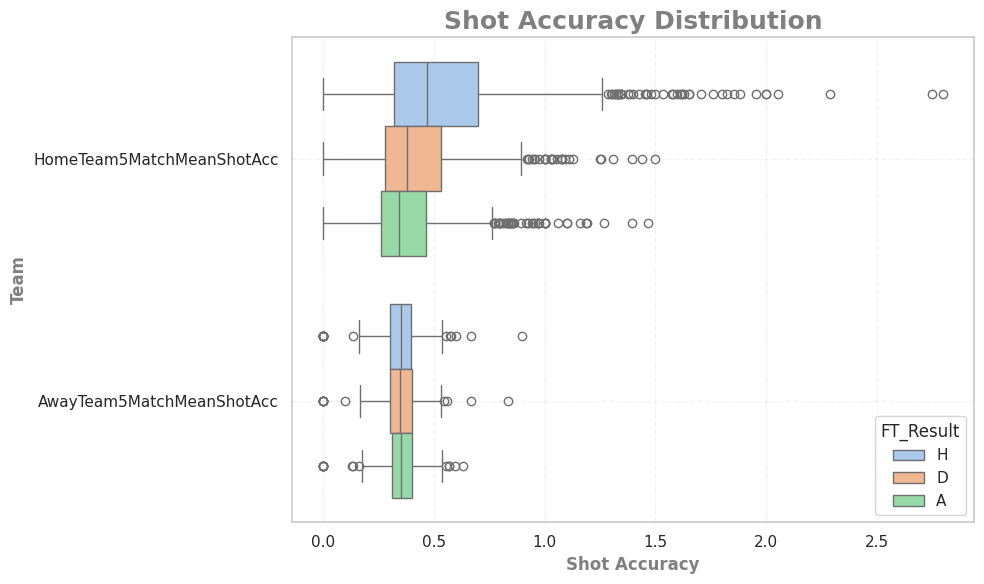

In [626]:
"""
What i am trying to understand is to see if the higher the last 5 match shot accuracy, the higher the chance of winning the game.
The aim is to show engineer a feature to show how good a team is in front of goal on average -> show attacking intent.
"""


train_df['HomeTeam5MatchMeanShotAcc'] = (train_df['HomeTeam5MatchShotsOTMean']/train_df['HomeTeam5MatchShotsMean']).fillna(0)
train_df['AwayTeam5MatchMeanShotAcc'] = (train_df['AwayTeam5MatchShotsOTMean']/train_df['AwayTeam5MatchShotsMean']).fillna(0)

melted_df = train_df[['HomeTeam5MatchMeanShotAcc', 'AwayTeam5MatchMeanShotAcc', 'FT_Result']].melt(
    id_vars=['FT_Result'],       # hue col
    var_name='Team',               # This will contain 'HomeTeam...' and 'AwayTeam...'
    value_name='Shot Accuracy'     # This will contain the actual numeric values
)


plt.figure(
    figsize=(10,6)
)

sns.boxplot(
    data=melted_df,
    x='Shot Accuracy',
    y='Team',
    hue='FT_Result',
    orient='h'
);

#adjust viz
adjust_visuals(
    title="Shot Accuracy Distribution",
    x_label="Shot Accuracy",
    y_label="Team"
);




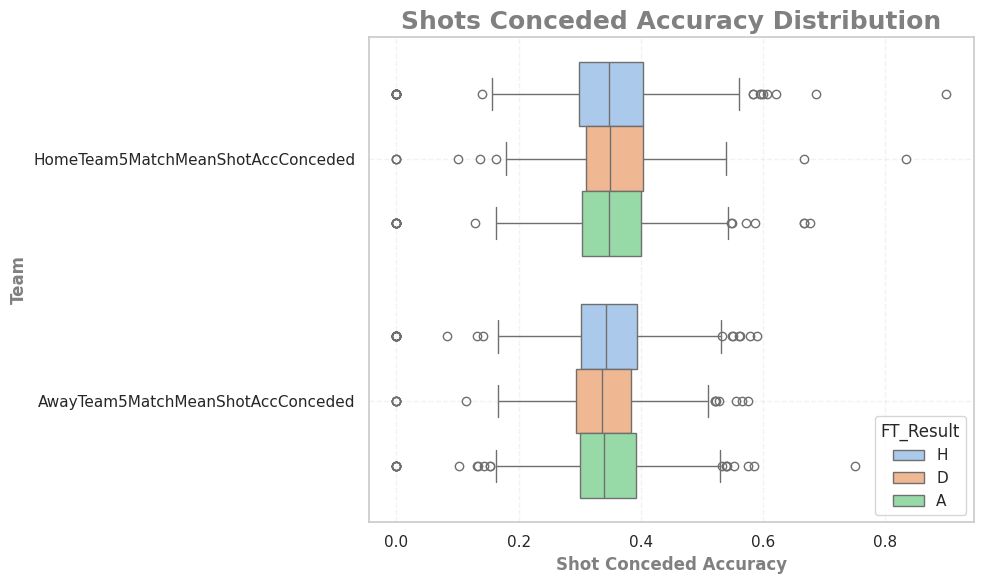

In [627]:
# for conceded, they want a low % value as it can indicate strong defense - ie putting off attackers as they strike.
train_df['HomeTeam5MatchMeanShotAccConceded'] = (train_df['HomeTeam5MatchShotsOTConcededMean']/train_df['HomeTeam5MatchShotsConcededMean']).fillna(0)
train_df['AwayTeam5MatchMeanShotAccConceded'] = (train_df['AwayTeam5MatchShotsOTConcededMean']/train_df['AwayTeam5MatchShotsConcededMean']).fillna(0)

melted_df = train_df[['HomeTeam5MatchMeanShotAccConceded', 'AwayTeam5MatchMeanShotAccConceded', 'FT_Result']].melt(
    id_vars=['FT_Result'],       # hue col
    var_name='Team',               # This will contain 'HomeTeam...' and 'AwayTeam...'
    value_name='Defence Accuracy'     # This will contain the actual numeric values
)

plt.figure(
    figsize=(10,6)
)

sns.boxplot(
    data=melted_df,
    x='Defence Accuracy',
    y='Team',
    hue='FT_Result',
    orient='h'
);

#adjust viz
adjust_visuals(
    title="Shots Conceded Accuracy Distribution",
    x_label="Shot Conceded Accuracy",
    y_label="Team"
);

**Notes**

The attacking and defensive histograms do not provide good signal due to the (roughly) evenly positioned distributions across all outcomes.

However, it does tell me that shot avg shot accuracy (both conceded and given) across 5 games typically lies between 30% and 40%. Across the Premier League teams, this is quite low but is likely impacted by the lower performing teams.

In [628]:
# create the features
x_train,x_val,x_test = shot_acc_feature(x_train),shot_acc_feature(x_val),shot_acc_feature(x_test)

x_train.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2280 entries, 2018-08-10 to 2024-05-19
Data columns (total 54 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   League Division                          2280 non-null   object 
 1   HomeTeam                                 2280 non-null   object 
 2   AwayTeam                                 2280 non-null   object 
 3   FT_HomeGoals                             2280 non-null   int64  
 4   FT_AwayGoals                             2280 non-null   int64  
 5   FT_Result                                2280 non-null   object 
 6   HT_HomeGoals                             2280 non-null   int64  
 7   HT_AwayGoals                             2280 non-null   int64  
 8   HT_Result                                2280 non-null   object 
 9   Match Referee                            2280 non-null   object 
 10  HomeShots                     

### Goals

In [629]:
def goals_for_and_against_match_avg(df:pd.DataFrame, team:str, sortby:str) -> pd.DataFrame:
  #df = df.copy()

  # group by selected team
  grp = df.groupby(team)

  # agg the data
  goals_for_and_against = (
    grp[['FT_HomeGoals','FT_AwayGoals']]
    .mean()
    .reset_index()
    .sort_values(by=sortby,ascending=False)
  )

  return goals_for_and_against


In [630]:
# which teams scores the most goals on avg per game?

scoring_teams = goals_for_and_against_match_avg(train_df,'HomeTeam','FT_HomeGoals')

# create colour matrix
scoring_teams.head(10).style.background_gradient(cmap='Blues')

,HomeTeam,FT_HomeGoals,FT_AwayGoals
16,Man City,2.859649,0.789474
14,Liverpool,2.456140,0.780702
0,Arsenal,2.087719,1.043860
23,Tottenham,1.912281,1.087719
17,Man United,1.842105,1.140351
7,Chelsea,1.763158,0.991228
1,Aston Villa,1.694737,1.421053
26,West Ham,1.614035,1.403509
18,Newcastle,1.587719,1.245614
13,Leicester,1.578947,1.231579


In [631]:
# which teams conceded the most on avg?


conceding_teams = goals_for_and_against_match_avg(train_df,'HomeTeam','FT_AwayGoals')

# create colour matrix
conceding_teams.head(10).style.background_gradient(cmap='Blues')


,HomeTeam,FT_HomeGoals,FT_AwayGoals
19,Norwich,0.815789,2.105263
25,West Brom,0.789474,2.052632
6,Cardiff,1.105263,2.000000
15,Luton,1.473684,1.947368
24,Watford,1.140351,1.771930
21,Sheffield United,0.964912,1.736842
12,Leeds,1.280702,1.684211
11,Huddersfield,0.526316,1.631579
22,Southampton,1.242105,1.589474
5,Burnley,1.042105,1.578947


Goals For & Against Correlation: 

               FT_HomeGoals  FT_AwayGoals
FT_HomeGoals          1.00         -0.79
FT_AwayGoals         -0.79          1.00




<Figure size 1000x800 with 0 Axes>

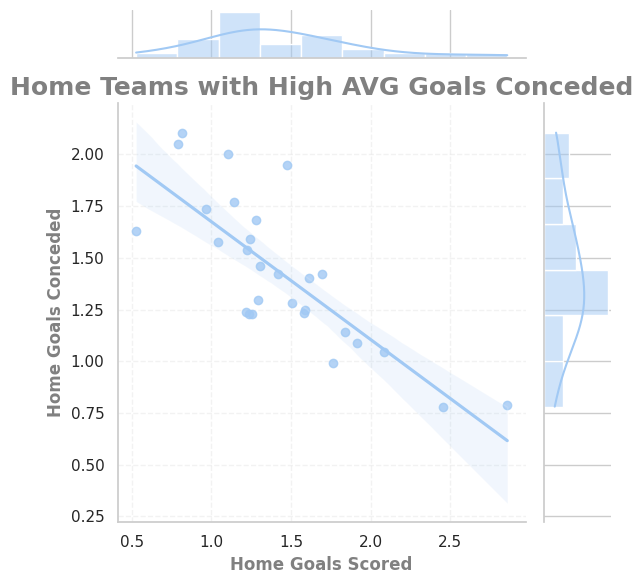

In [632]:
# show the distribution and relationships
corr_tb = conceding_teams.select_dtypes(exclude=['object']).corr()
corr_tb = corr_tb.round(2)
print(f"Goals For & Against Correlation: \n\n {corr_tb}\n\n")
plt.figure(
    figsize=(10,8)
)

sns.jointplot(
    data=conceding_teams,
    x='FT_HomeGoals',
    y='FT_AwayGoals',
    kind='reg'
  )


# format the plot
adjust_visuals(
    title="Home Teams with High AVG Goals Conceded",
    x_label="Home Goals Scored",
    y_label="Home Goals Conceded"
);

In [633]:
# do the same for the away team
# which teams conceded the most on avg?
away_conceding_teams = goals_for_and_against_match_avg(train_df,'AwayTeam','FT_AwayGoals')

# create colour matrix
away_conceding_teams.head(10).style.background_gradient(cmap='Blues')

,AwayTeam,FT_HomeGoals,FT_AwayGoals
16,Man City,0.815789,2.131579
14,Liverpool,1.070175,1.903509
23,Tottenham,1.500000,1.675439
0,Arsenal,1.219298,1.631579
7,Chelsea,1.394737,1.578947
13,Leicester,1.568421,1.568421
17,Man United,1.421053,1.456140
12,Leeds,2.017544,1.385965
3,Brentford,1.649123,1.333333
15,Luton,2.526316,1.263158


Goals For & Against Correlation: 

               FT_HomeGoals  FT_AwayGoals
FT_HomeGoals          1.00         -0.67
FT_AwayGoals         -0.67          1.00




<Figure size 1000x800 with 0 Axes>

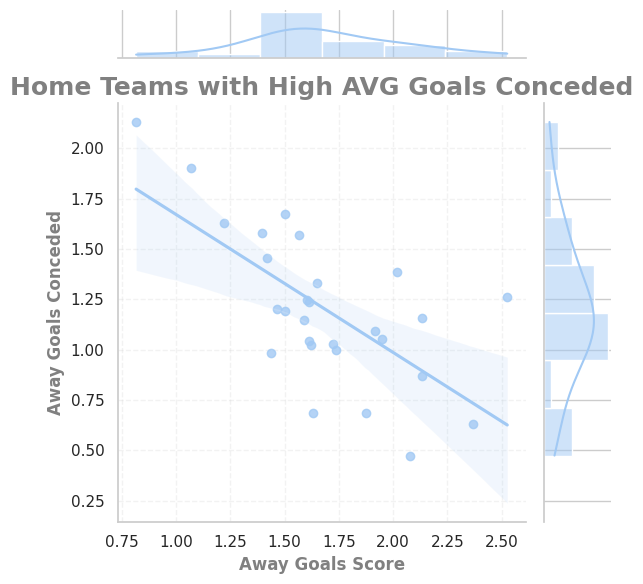

In [634]:
# show the distribution and relationships
corr_tb = away_conceding_teams.select_dtypes(exclude=['object']).corr()
corr_tb = corr_tb.round(2)
print(f"Goals For & Against Correlation: \n\n {corr_tb}\n\n")
plt.figure(
    figsize=(10,8)
)

sns.jointplot(
    data=away_conceding_teams,
    x='FT_HomeGoals',
    y='FT_AwayGoals',
    kind='reg'
  )


# format the plot
adjust_visuals(
    title="Home Teams with High AVG Goals Conceded",
    x_label="Away Goals Score",
    y_label="Away Goals Conceded"
);

**Notes**

More signal! It appears our observations show a strong negative linear relationship between average home team goals scored and conceded per game. This means that, according to the relationship, for every increase in average goals scored per game the teams average goals conceded per game decreases.

When the data was ordered, you could see established Premier league teams scoring the most goals on average per game while lesser established tea,s ie newly promoted teams, typically score less and concede more per game on average.

When I switched the team to away team, the relationship weakened by 0.12 points due to the points on the scatter graph being more spread across the plane. In other words, there is a lot more variability in avg scored and conceded for the away team suggesting groups of teams, although have similar avg goals scored per game, vary more in terms of their goals conceded. From a predictability standpoint, we require further information as to what is influencing the variability - is it the team? is it a group of teams ie newly promoted teams?

For the ML part of this project, we will struggle to predict match outcomes for newly promoted teams as there is little information on them. However, we could use other histroic newly promoted sides as a proxy to extract some information.

What will be intersting to see is how the relationships are observed when we introduce the match outcome.

In [635]:
# create the features
train_df = rolling_goals_for_and_against(train_df)

train_df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2280 entries, 2018-08-10 to 2024-05-19
Data columns (total 72 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   League Division                          2280 non-null   object 
 1   HomeTeam                                 2280 non-null   object 
 2   AwayTeam                                 2280 non-null   object 
 3   FT_HomeGoals                             2280 non-null   int64  
 4   FT_AwayGoals                             2280 non-null   int64  
 5   FT_Result                                2280 non-null   object 
 6   HT_HomeGoals                             2280 non-null   int64  
 7   HT_AwayGoals                             2280 non-null   int64  
 8   HT_Result                                2280 non-null   object 
 9   Match Referee                            2280 non-null   object 
 10  HomeShots                     

#### Previous Match Influence

Goals For & Against Correlation: 

                              HomeTeamLastGameGoalsScored  FT_HomeGoals
HomeTeamLastGameGoalsScored                         1.00          0.11
FT_HomeGoals                                        0.11          1.00




<Figure size 1000x800 with 0 Axes>

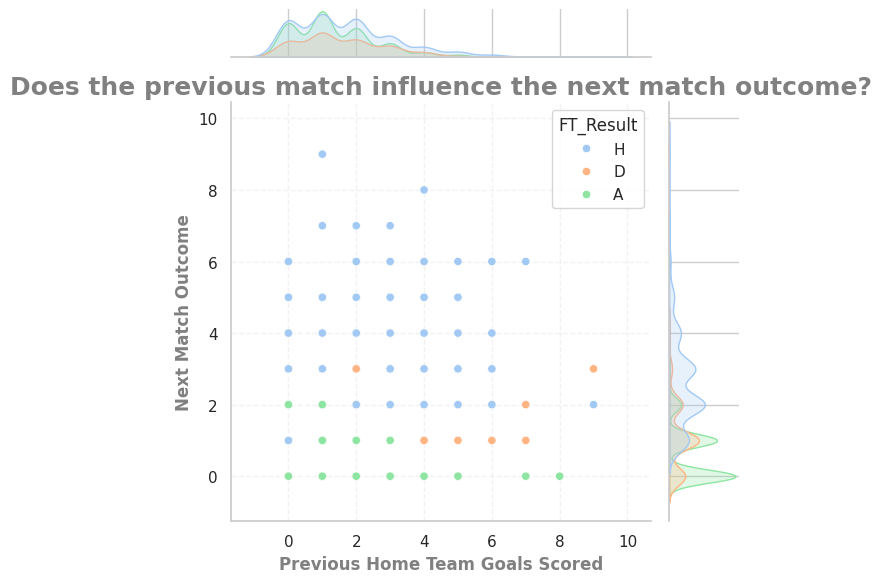

In [636]:
show_the_relartionship(
    df=train_df,
    var1='HomeTeamLastGameGoalsScored',
    var2='FT_HomeGoals',
    result='FT_Result',
    kind='scatter',
    title="Does the previous match influence the next match outcome?",
    x_label="Previous Home Team Goals Scored",
    y_label="Next Match Outcome"
)


Goals For & Against Correlation: 

                                HomeTeamLastGameGoalsConceded  FT_AwayGoals
HomeTeamLastGameGoalsConceded                            1.0           0.1
FT_AwayGoals                                             0.1           1.0




<Figure size 1000x800 with 0 Axes>

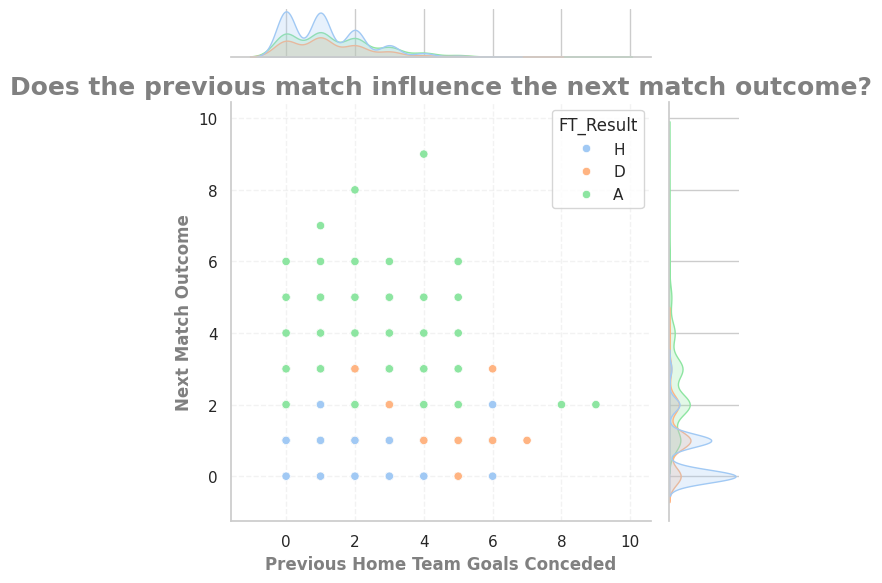

In [637]:
show_the_relartionship(
    df=train_df,
    var1='HomeTeamLastGameGoalsConceded',
    var2='FT_AwayGoals',
    result='FT_Result',
    kind='scatter',
    title="Does the previous match influence the next match outcome?",
    x_label="Previous Home Team Goals Conceded",
    y_label="Next Match Outcome"
)


**Notes**

The relationship shows very little information into the influence of the previous game has on the next. However, a better way to show this data would be to do what we did with the goals - place into buckets and conduct chi2 test!


In [638]:
"""

the test:

H0: There is no dependency between previous home team goals scored and next match outcome.
H1: There is a dependency between previous home team goals scored and next match outcome.

"""

# create buckets for the goals scored and conceded for both home and away teams

def goal_bucket(goals):
  if goals>=4:
    return '4+'
  elif goals>=2:
    return '2-3'
  else:
    return '0-1'

train_df['HomeGoalsBucket'] = train_df['FT_HomeGoals'].apply(goal_bucket)
train_df['AwayGoalsBucket'] = train_df['FT_AwayGoals'].apply(goal_bucket)

train_df['PreviousMatchHomeGoalsBucket'] = train_df['HomeTeamLastGameGoalsScored'].apply(goal_bucket)
train_df['PreviousMatchAwayGoalsBucket'] = train_df['AwayTeamLastGameGoalsScored'].apply(goal_bucket)



tbl = run_chi2_test(
    var1=train_df['PreviousMatchHomeGoalsBucket'],
    target=train_df['FT_Result'],
    confidence=0.05
)

# show the results
tbl


Reject Null Hypothesis -> There is evidence that the features are dependent
**************************************************
Chi2 Value: 30.55
P-Value: 0.00
Degrees of Freedom: 4
Expected Value: 
[[420.55701754 279.07675439 565.36622807]
 [273.94385965 181.78596491 368.27017544]
 [ 63.49912281  42.1372807   85.36359649]]
**************************************************


FT_Result,A,D,H
PreviousMatchHomeGoalsBucket,,,
0-1,470,273,522
2-3,249,190,385
4+,39,40,112


In [639]:
train_df['PreviousMatchHomeGoalConcededBucket'] = train_df['HomeTeamLastGameGoalsConceded'].apply(goal_bucket)
train_df['PreviousMatchAwayGoalsConcededBucket'] = train_df['AwayTeamLastGameGoalsConceded'].apply(goal_bucket)


tbl = run_chi2_test(
    var1=train_df['PreviousMatchHomeGoalConcededBucket'],
    target=train_df['FT_Result'],
    confidence=0.05
)

# show the results
tbl


Reject Null Hypothesis -> There is evidence that the features are dependent
**************************************************
Chi2 Value: 21.94
P-Value: 0.00
Degrees of Freedom: 4
Expected Value: 
[[484.38859649 321.43464912 651.17675439]
 [235.37894737 156.19473684 316.42631579]
 [ 38.23245614  25.37061404  51.39692982]]
**************************************************


FT_Result,A,D,H
PreviousMatchHomeGoalConcededBucket,,,
0-1,442,327,688
2-3,261,153,294
4+,55,23,37


In [640]:
# review how both features interact
# create contingency table
tbl = run_chi2_test(
    var1=[
        train_df['PreviousMatchHomeGoalConcededBucket'],
        train_df['PreviousMatchHomeGoalsBucket']
          ],
    target=train_df['FT_Result'],
    confidence=0.05
)

# show the results
tbl


Reject Null Hypothesis -> There is evidence that the features are dependent
**************************************************
Chi2 Value: 53.54
P-Value: 0.00
Degrees of Freedom: 16
Expected Value: 
[[249.6745614  165.68114035 335.64429825]
 [188.83508772 125.30877193 253.85614035]
 [ 45.87894737  30.44473684  61.67631579]
 [141.29385965  93.76096491 189.94517544]
 [ 77.12982456  51.18245614 103.6877193 ]
 [ 16.95526316  11.25131579  22.79342105]
 [ 29.58859649  19.63464912  39.77675439]
 [  7.97894737   5.29473684  10.72631579]
 [  0.66491228   0.44122807   0.89385965]]
**************************************************


In [641]:
"""

the test:

H0: There is no dependency between previous home team goals scored and next match outcome.
H1: There is a dependency between previous home team goals scored and next match outcome.

"""

tbl = run_chi2_test(
    var1=train_df['PreviousMatchAwayGoalsBucket'],
    target=train_df['FT_Result'],
    confidence=0.05
)

# show the results
tbl


Reject Null Hypothesis -> There is evidence that the features are dependent
**************************************************
Chi2 Value: 29.15
P-Value: 0.00
Degrees of Freedom: 4
Expected Value: 
[[482.06140351 319.89035088 648.04824561]
 [236.04385965 156.63596491 317.32017544]
 [ 39.89473684  26.47368421  53.63157895]]
**************************************************


FT_Result,A,D,H
PreviousMatchAwayGoalsBucket,,,
0-1,446,325,679
2-3,249,151,310
4+,63,27,30


In [642]:
"""

the test:

H0: There is no dependency between previous home team goals scored and next match outcome.
H1: There is a dependency between previous home team goals scored and next match outcome.

"""

tbl = run_chi2_test(
    var1=train_df['PreviousMatchAwayGoalsConcededBucket'],
    target=train_df['FT_Result'],
    confidence=0.05
)

# show the results
tbl

Fail to Reject Null Hypothesis
**************************************************
Chi2 Value: 8.73
P-Value: 0.07
Degrees of Freedom: 4
Expected Value: 
[[420.55701754 279.07675439 565.36622807]
 [273.61140351 181.56535088 367.82324561]
 [ 63.83157895  42.35789474  85.81052632]]
**************************************************


FT_Result,A,D,H
PreviousMatchAwayGoalsConcededBucket,,,
0-1,442,284,539
2-3,264,181,378
4+,52,38,102


In [643]:
"""

the test:

H0: There is no dependency between previous home team goals scored and next match outcome.
H1: There is a dependency between previous home team goals scored and next match outcome.

"""

tbl = run_chi2_test(
    var1=[
        train_df['PreviousMatchAwayGoalsConcededBucket'],
        train_df['PreviousMatchAwayGoalsBucket']
        ],
    target=train_df['FT_Result'],
    confidence=0.05
)

# show the results
tbl

Reject Null Hypothesis -> There is evidence that the features are dependent
**************************************************
Chi2 Value: 41.32
P-Value: 0.00
Degrees of Freedom: 16
Expected Value: 
[[248.67719298 165.01929825 334.30350877]
 [140.96140351  93.54035088 189.49824561]
 [ 30.91842105  20.51710526  41.56447368]
 [187.50526316 124.42631579 252.06842105]
 [ 78.12719298  51.84429825 105.02850877]
 [  7.97894737   5.29473684  10.72631579]
 [ 45.87894737  30.44473684  61.67631579]
 [ 16.95526316  11.25131579  22.79342105]
 [  0.99736842   0.66184211   1.34078947]]
**************************************************


**Notes**

The previous match goals conceded influences the next match a team plays!

1. The mentality effect is non-linear — the impact of conceding 0-1 vs 2-3 is moderate, but 4+ represents a psychological impact on the home team -> a quantification of how conceding 4+ goals influences the teams play in the next home game.

2. The home team scoring 4+ goals in their previous home game suggests something similar - a quantification of confidence in the players that is transferred into the next game!

3. It appears that a match that contains 8+ goals (goals for and against) are a rare event, but when it has happened the next match ended in an away team victory. Due to lack of data, no conclusions should be drawn but I wonder if an exciting previous home game negatively impacts the players mindset?

4. for Away teams, the data tells a different story! We failed to reject the Null hypothesis for Away Team Goals Conceded at the 5% threshold, which means there is little evidence to suggest that the previous match goals conceded for the away team influences their next match. Comparing this to the results obtained for the home teams, it suggests that the goals they concede have minor influence on their performance and mindset into their next away game, whereas the opposite is true for home teams. Perhaps this is the influence of the pressure and attitude applied by the home crowd when they see their team concede lots of goals. In theory, therefore, there is less pressure on away teams going into their next games.

(In theory, i could reject at 10% but I decided not to as I do not want to run the risk of Type 1 Errors)

5. We then observe Simpson Paradox for that feature as the introduction of Goals scored in the previous match for the away team flips the results for us to be able to reject the Null Hypothesis. This means the two features play a key role in determining the match outcome for the next match, meaning the proportion of goals scored relative to conceded influences the Away teams performance - a confidence boost or decline. However, this is likely just a small part of the story as the team they face and their home record will infleunce such matters.

In [644]:
# create the features for train, val and test
x_train,x_val,x_test = rolling_goals_for_and_against(x_train),rolling_goals_for_and_against(x_val),rolling_goals_for_and_against(x_test)

x_train.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2280 entries, 2018-08-10 to 2024-05-19
Data columns (total 66 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   League Division                          2280 non-null   object 
 1   HomeTeam                                 2280 non-null   object 
 2   AwayTeam                                 2280 non-null   object 
 3   FT_HomeGoals                             2280 non-null   int64  
 4   FT_AwayGoals                             2280 non-null   int64  
 5   FT_Result                                2280 non-null   object 
 6   HT_HomeGoals                             2280 non-null   int64  
 7   HT_AwayGoals                             2280 non-null   int64  
 8   HT_Result                                2280 non-null   object 
 9   Match Referee                            2280 non-null   object 
 10  HomeShots                     

In [645]:
# can a team hold a lead? ie winning at the half and end the game with a win

## Probability

### Binomial

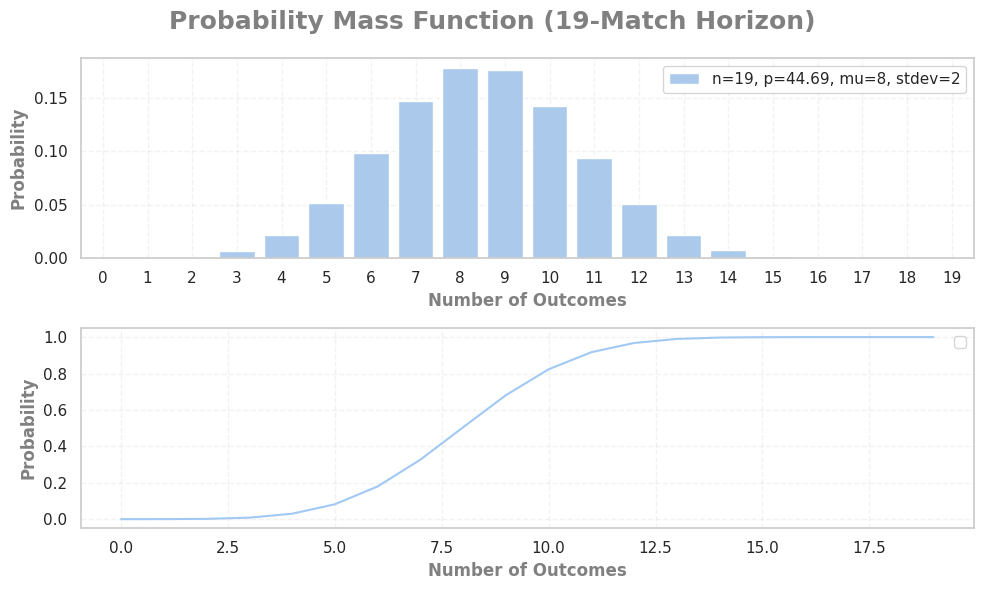

In [646]:
"""
The data we are dealing with has 3 outcomes - win, loss, draw. However, due to the flexibility of the Binomial, we can set win as our target/success while
the other 2 outcomes as fail.

Does our data meet the assumptions?

1. Each match/trial is independent -> although the Chi2 says otherwise, each home match is not played every week, it is more every 1-2 weeks depending
on what events are on such as Cup games. Moreover, each game conatins different teams where their result has no influence on each other.
Therefore, we can assume that each match outcome is independent.
2. p is constant for each trial -> this will be assumed for the purpose of this experiement.
3. We have 2 outcomes.
4. we will fix n trials and our sample size is fixed.


The question we want to answer is what is the expected win per season (19 games) for the home team?

"""
binom_obj = ProbabilityModelling(train_df,'H')

# run binomial
binom_obj.run_model(model_type='binomial',method_of_prep='frequentist')


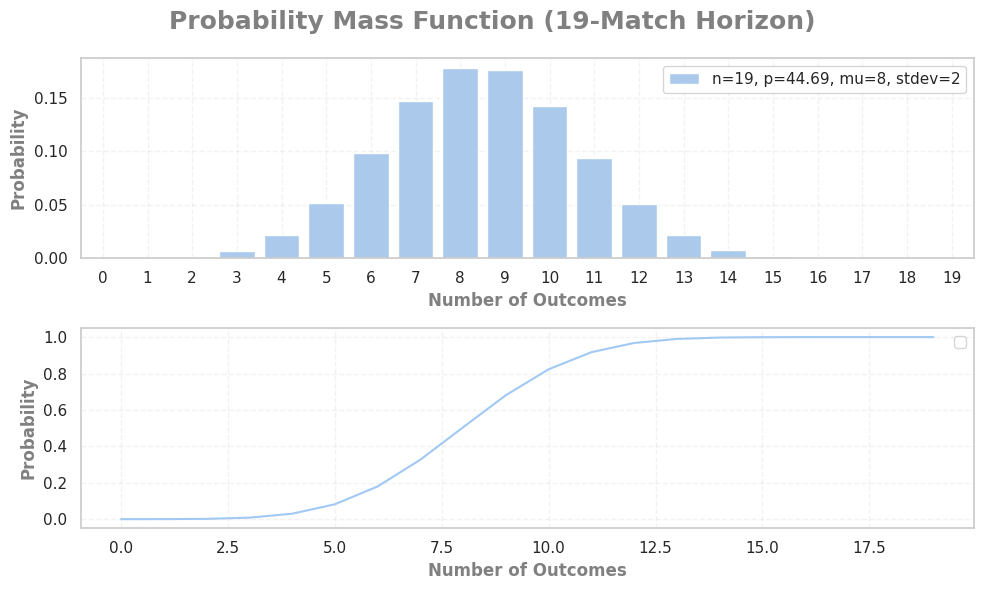

In [647]:
"""
We saw established and new teams to the prem with considerably different goals for and against as home side.

Lets compare the expected wins for these teams to see see their expected wins.
The aim is to see if we can engineer a Prior for these teams to give the model some signal
as to which team should win their next match. Very similar to how we reason with matches in the Premier League, where we expect
strong performing Home sides, such as Man City, to win their next home game, and are shocked when they lose!

I will compare Man City home wins against Norwich.

To make it fair. I will sample the data where they were in the same season.

"""

seasons = train_df['Season'].loc[train_df['HomeTeam']=='Norwich'].unique()

mask = (train_df['Season'].isin(seasons))*(train_df['HomeTeam']=='Norwich')
NorwichDf = train_df.loc[mask]

norwich_obj = ProbabilityModelling(train_df,'H')

# run binomial
norwich_obj.run_model(model_type='binomial',method_of_prep='frequentist')

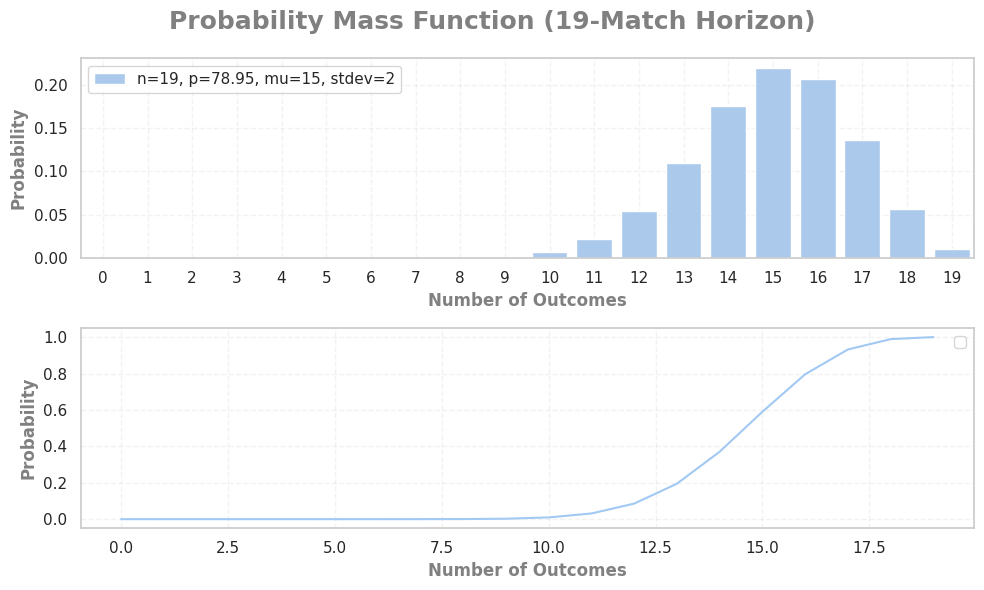

In [648]:
seasons = train_df['Season'].loc[train_df['HomeTeam']=='Norwich'].unique()

mask = (train_df['Season'].isin(seasons))*(train_df['HomeTeam']=='Man City')
McDf = train_df.loc[mask]

mcObj = ProbabilityModelling(McDf,'H')

# run geometric
mcObj.run_model(model_type='binomial',method_of_prep='frequentist')


### Geometric Distribution

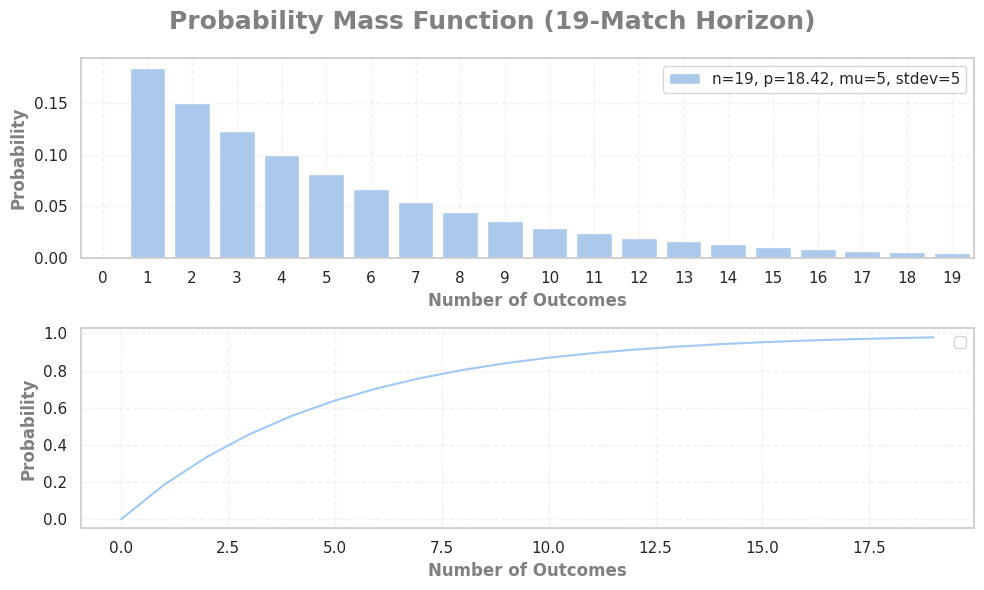

In [649]:
"""
We have observed that expected wins at team level in a season of 19 home games is vastly different, which can give us important information
to identify the outcome by using this data as a Prior (this is to come).

Moreover, it has shown that the team itself is a great feature because the name holds signal relating to its
home or away performanc, which enables the model to predict the match outcome. However, feature engineering is likely
required as having all teams as features will be costly, which means we may have to do some feature reduction through PCA.

What we have not observed is how many trials (matches) it will take for these teams to win a game.
In other words, for Norwich and Man City how many matches are they to play until they realise a home win?
Given what we know from the Binomial, I expect Man City to wait, on avg, 1 match while Norwich at least 10.
"""

# agg the data to get p
seasons = train_df['Season'].loc[train_df['HomeTeam']=='Norwich'].unique()

mask = (train_df['Season'].isin(seasons))*(train_df['HomeTeam']=='Norwich')
NorwichDf = train_df.loc[mask]

# run the geometric dist
Norwich_obj = ProbabilityModelling(NorwichDf,'H')
Norwich_obj.run_model(model_type='geometric',method_of_prep='frequentist')

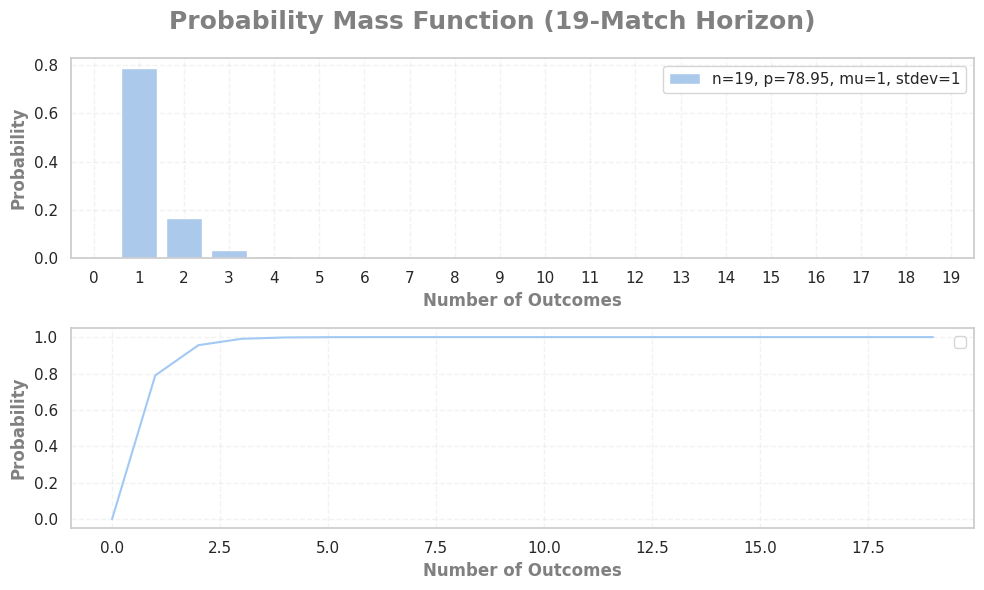

In [650]:
# agg the data to get p
seasons = train_df['Season'].loc[train_df['HomeTeam']=='Norwich'].unique()

mask = (train_df['Season'].isin(seasons))*(train_df['HomeTeam']=='Man City')
mcDf = train_df.loc[mask]

# run the geometric dist
mc_obj = ProbabilityModelling(mcDf,'H')
mc_obj.run_model(model_type='geometric',method_of_prep='frequentist')

**Notes**

The contrasting differences between the successful home team and unsuccessful home team is strikingly different! What we are observing is the quantification of likelihood of a team winning n games in a 19 game season (home games only) and the likelihood of a team winning in their next n games.

For Man City (the strong team), they have a strong likelihood that they will win their next game, whereas Norwich is the opporsite. Their distribution slowly declines after each trial (match), which means that there are small differences in likelihood in Norwich winning a game in n amount if trials. This visualisation shows what a great and a bad home team look like, which links nicely to Bayesian reasoning where fans predict outcomes based on what they have observed (the visuals) which we will explore next.

### Bayesian

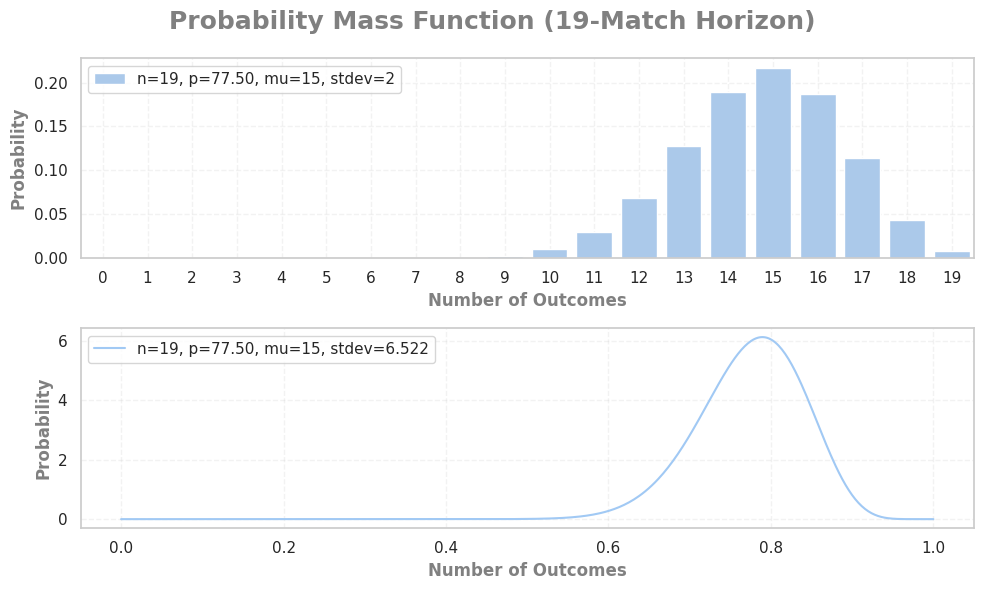

In [651]:

# run beta-binomial
mcObj.run_model(model_type='beta-binomial',method_of_prep='bayesian',prior='uninformative')

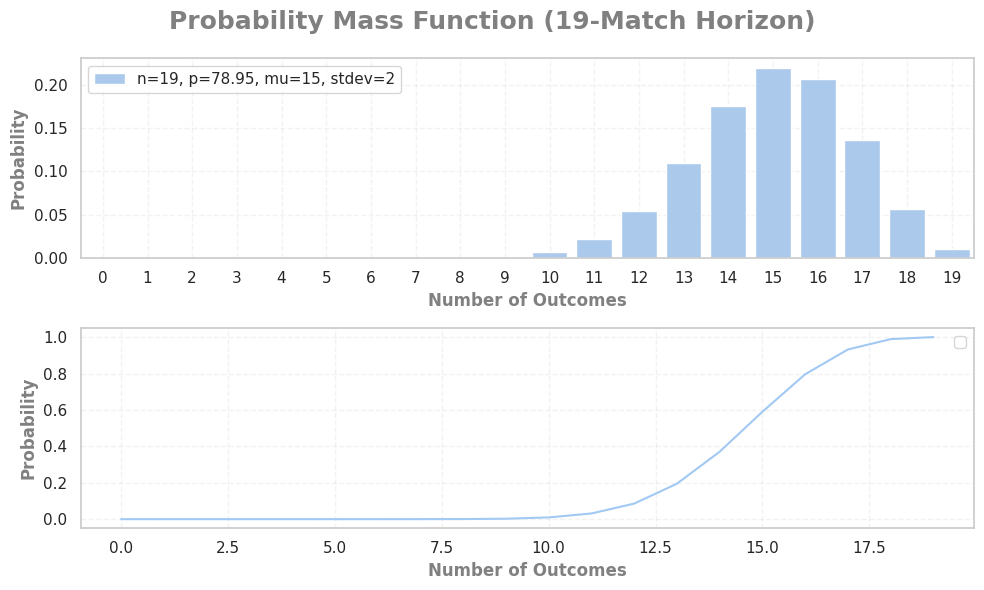

In [652]:
mcObj.run_model(model_type='binomial',method_of_prep='frequentist')

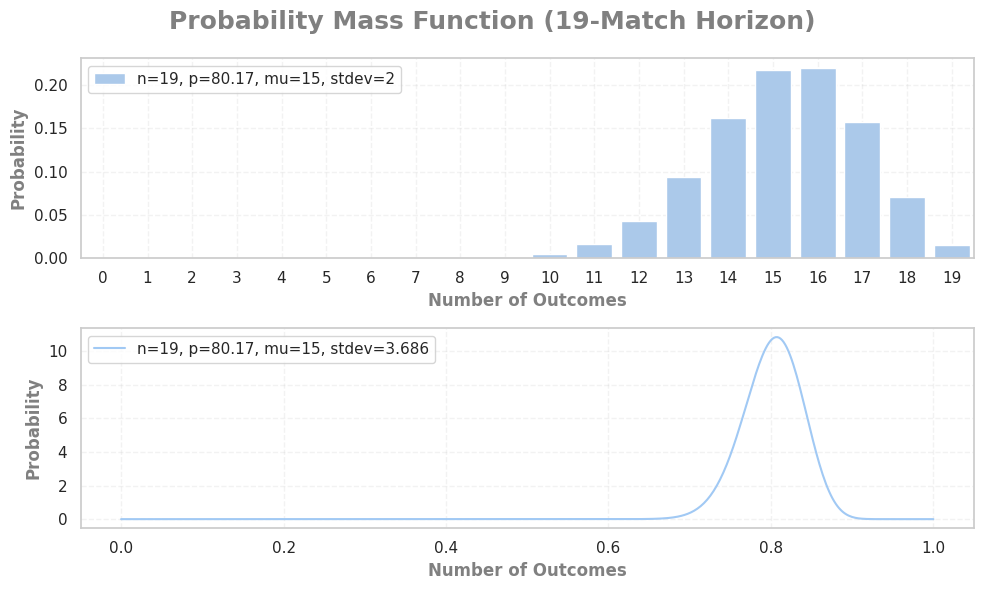

In [653]:
# what happens when we give the model all the data, what changes when we get more information?
mask = (train_df['HomeTeam']=='Man City')
all_data_McDf = train_df.loc[mask]

all_data_mcObj = ProbabilityModelling(all_data_McDf,'H')

# run the bayesian model
all_data_mcObj.run_model(model_type='beta-binomial',method_of_prep='bayesian',prior='uninformative')

**Notes**

the Bayesian analysis shows revealed the following:

1. Too little information (data) leads to a wide Posterior Distribution by using an Uninformative Prior. This is because we were only using 2 seasons-worth of data, which is not a significant amount to make judgements on the outcome. In terms of our ML model, this will be encountered when we come across teams that have not entered the league ever or in a long time - with have no information on how they will likely to perform at home or away. However, as I mentioned earlier, proxies can be used to give some information about these teams. This method is very similar to that of adding in Prior data as to how newly promoted teams performed at home or away historically, how the newly promoted teams performed against established teams or top 6 / big 6. Therefore, I shall creat features that will act as prior information in the feature set with the aim to give the model some information to effectively predict the match outcome.

2. By increasing our data size, we shifted our Binomial and Beta to the right -> this is the direct effect of updating our model with new information. However, what I didn't do was update my Prior as I simply gave the model more data. That being said, we still have a tighter Posterior distribution in comparison to using 2 seasons worth of data.

The next step is to see what happens when i update my Priors with new information and how my Posterior and Binomial Distribution will change.

In [545]:
def adjust_season(season_str):
    # convert to int for easier reduction
    start_num = int(season_str[:2])
    end_num = int(season_str[2:])

    # subtract one year
    start_num -= 1
    end_num -= 1

    # convert back to 2-digit strings with leading zeros
    start_str = str(start_num).zfill(2)
    end_str = str(end_num).zfill(2)

    # combine into season string
    return start_str + end_str

def team_status(df:pd.DataFrame) -> pd.DataFrame:
  df = df.copy()

  # create a dict containing each team by season
  season_team_map = df.groupby("Season")["HomeTeam"].apply(set).to_dict()
  season_away_team_map = df.groupby("Season")["AwayTeam"].apply(set).to_dict()

  # helper col
  df["PreviousSeason"] = df["Season"].apply(adjust_season)

  # create the features
  df["HomeTeamLeagueStatus"] = df.apply(
      lambda row: "Newly Promoted"
                  if row['Season'] != '1819' and row["HomeTeam"] not in season_team_map.get(row["PreviousSeason"] , set())
                  else "Established",
      axis=1
  )

  df["AwayTeamLeagueStatus"] = df.apply(
      lambda row: "Newly Promoted"
                  if  row['Season'] != '1819' and row["AwayTeam"] not in season_team_map.get(row["PreviousSeason"] , set())
                  else "Established",
      axis=1
  )

  # drop helper col
  df.drop(columns=['PreviousSeason'],inplace=True)

  return df






In [352]:
  # manuualy map the 3 teams promoted in 1819 season
  train_df["HomeTeamLeagueStatus"] = df.apply(
      lambda x: "Newly Promoted"
      if x['HomeTeam'] in ['Wolves','Cardiff','Fulham'] and x['Season'] =='1819'
      else x.get('HomeTeamLeagueStatus', 'Established'),
      axis=1
  )



ValueError: cannot reindex on an axis with duplicate labels

In [546]:
train_df = team_status(df=train_df)
train_df.pivot_table(
    index='HomeTeamLeagueStatus',
    columns='Season',
    values='FT_Result',
    aggfunc='value_counts'
)

Season                           1819   1920   2021   2122   2223   2324
HomeTeamLeagueStatus FT_Result                                          
Established          A          128.0   89.0  124.0   92.0   89.0   86.0
                     D           71.0   83.0   68.0   80.0   72.0   70.0
                     H          181.0  151.0  131.0  151.0  162.0  167.0
Newly Promoted       A            NaN   27.0   29.0   37.0   20.0   37.0
                     D            NaN    9.0   15.0    8.0   15.0   12.0
                     H            NaN   21.0   13.0   12.0   22.0    8.0

In [356]:
"""
First I need to group teams to see if they're an established team or
a newly promoted one.


"""


# helper col
#train_df["PreviousSeason"] = train_df["Season"].apply(adjust_season)

# create a dict containing each team by season
#season_team_map = train_df.groupby("Season")["HomeTeam"].apply(set).to_dict()
#season_away_team_map = train_df.groupby("Season")["AwayTeam"].apply(set).to_dict()

# create the features

train_df["HomeTeamLeagueStatus"] = train_df.apply(
    lambda row: "Newly Promoted"
                if row['Season'] != '1819' and row["HomeTeam"] not in season_team_map.get(row["PreviousSeason"] , set())
                else "Established",
    axis=1
)

train_df["AwayTeamLeagueStatus"] = train_df.apply(
    lambda row: "Newly Promoted"
                if  row['Season'] != '1819' and row["AwayTeam"] not in season_team_map.get(row["PreviousSeason"] , set())
                else "Established",
    axis=1
)

# manuualy map the 3 teams promoted in 1819 season
train_df["HomeTeamLeagueStatus"] = train_df.apply(
    lambda x: "Newly Promoted"
    if x['HomeTeam'] in ['Wolves','Cardiff','Fulham'] and x['Season'] =='1819'
    else x.get('HomeTeamLeagueStatus', 'Established'),
    axis=1
)

train_df.drop(columns=['PreviousSeason'],inplace=True)

train_df.pivot_table(
    index='HomeTeamLeagueStatus',
    columns='Season',
    values='FT_Result',
    aggfunc='value_counts'
)

NameError: name 'season_team_map' is not defined

In [547]:
"""
We have now increased our information for teams like Norwich, lets see how confident we can be
when we use this data to quantify the likelihood of winning certain number of games in a season
"""

newlyPromoted_mask = train_df['HomeTeamLeagueStatus']=='Newly Promoted'
newlyPromotedDf = train_df.loc[newlyPromoted_mask].copy()

newlyPromotedDf['FT_Result'].value_counts(normalize=True).reset_index()

,FT_Result,proportion
0,A,0.526316
1,H,0.266667
2,D,0.207018


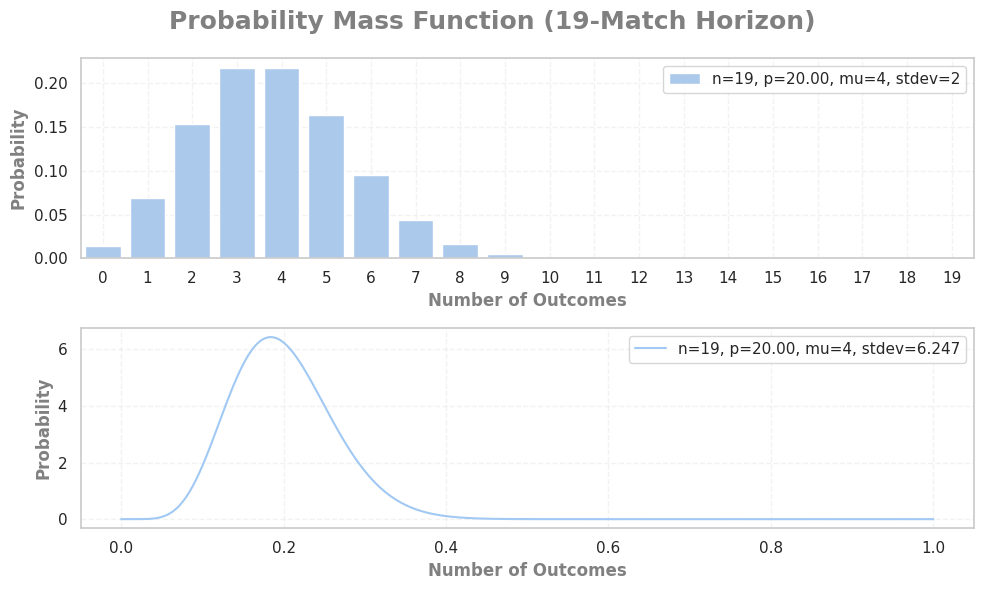

In [548]:
Norwich_obj.run_model(model_type='beta-binomial',method_of_prep='bayesian',prior='uninformative')

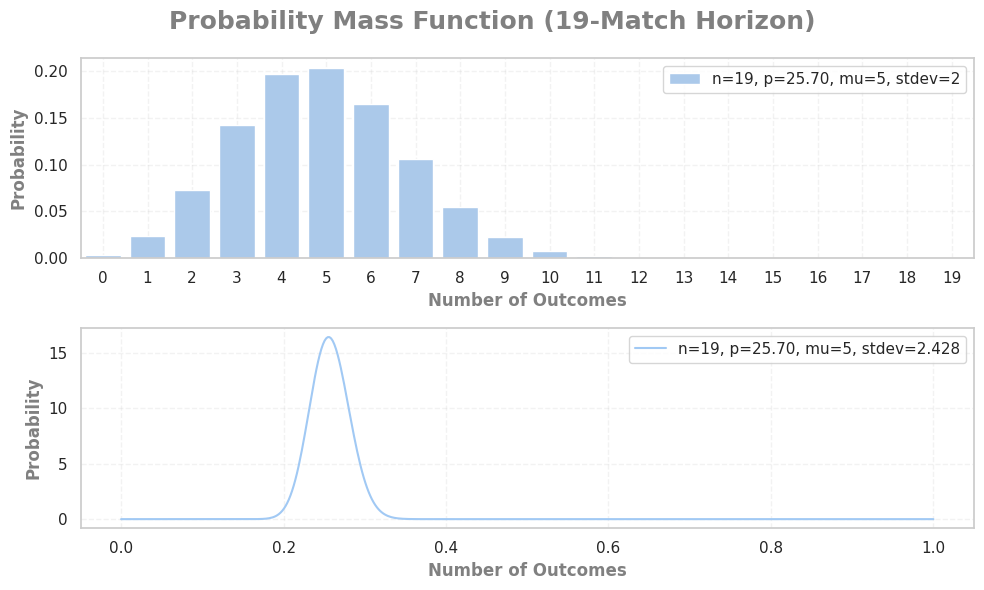

In [549]:
# lets run the probability model
Norwich_obj.run_model(
    model_type='beta-binomial',
    method_of_prep='bayesian',
    prior='global',
    all_data=train_df,
    team_status="Newly Promoted"
    )

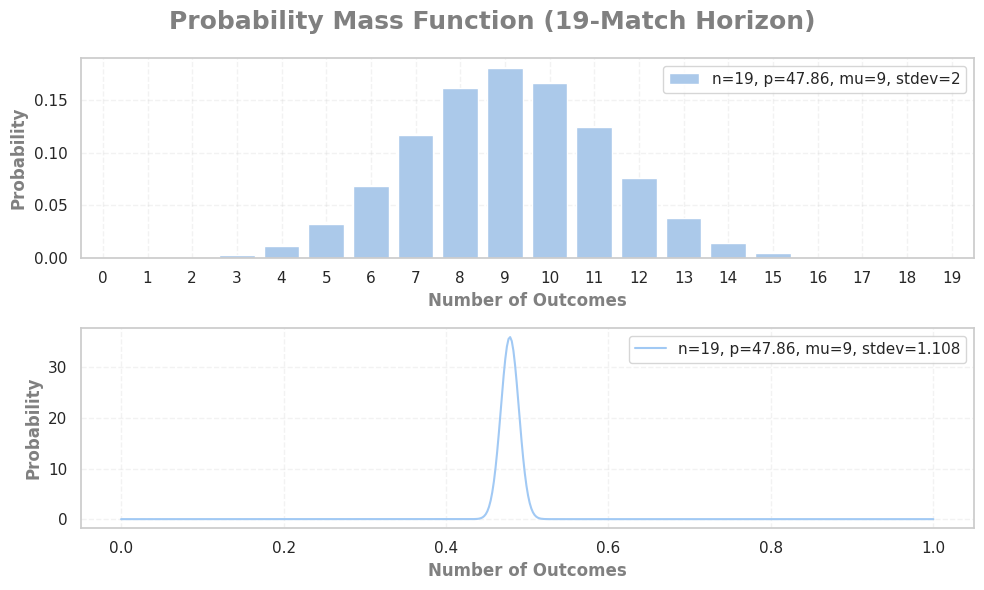

In [550]:
"""
How does this prioir influence Man City?

I am keen to understand whether adding a prior for all established teams
will degrade the Posterior Distribution due to Teams like Fulham and Nottingham Forest.
"""

mcObj = ProbabilityModelling(mcDf,'H')
mcObj.run_model(model_type='beta-binomial',method_of_prep='bayesian',prior='global',all_data=train_df,team_status="Established")

**Notes**

By adding the feature to determine newly promoted teams, I have observed the following:

1. The Posterior Distribution shows increased confidence due to the reduction of the standard deviation - Updating the Prior to Global for Newly Promoted Teams provided the probability model more confident information as to where the probability (p) lies for these teams.

2. For new teams coming into the league, we can expected them to win 5 home games in the season on average. From a supporter standpoint, this is not good at all as each of these new teams need to maximise their home wins due to having the support of the home crowd.

3. It would be interesting to see how the global prior updates with each season as we could see these teams improving by winning more home games. Therefore, it is important that the prior for these types of teams are updated as each game passes.

4. The introduction of the Prior for newly promoted teams has provided the quantification of Football fans belief when they go into seasons not knowing the opposition. For example, a supporter of the away side will be highly confident that they will beat the newly promoted team or draw, but will be shocked for the event that they lose the match.

5. You could argue that the Newly Promoted Team Prior has placed over confidence in Norwich probability of winning a game in the Premier League as it has shifted the distributions to the right (Binomial mu increased by 1 match and Beta mu has increased by 7.63%). However, this signal will provide the ML model signal for teams where we have limited information by using the label and a prior value feature to predict the match outcome. My money is these teams losing or drawing!

6. Finally, when applying the global prior for Man City it draws the distributions to the left which is a visual representation of the dangers of Global Priors. This is because it is being influenced by the teams who are established but do not perform as well as a team like Man City. Therefore, the prior for this type of team should be data from the Top 6 teams, while the remaining will be labelled as either newly promoted or average team.

### Poisson

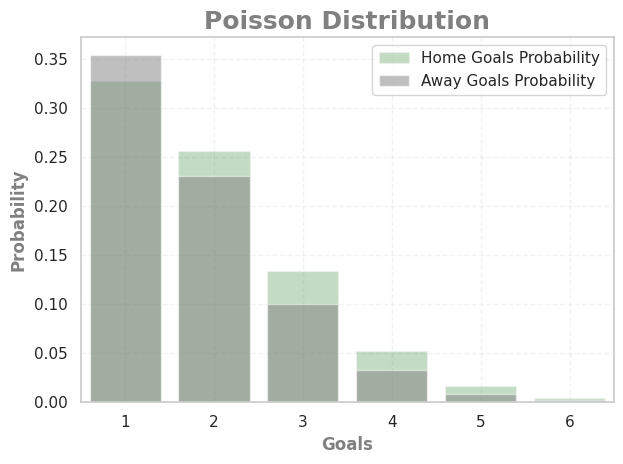

In [674]:
"""
Within this section, I want to find out if i can model the expected goals per game. I can apply the
Poisson Dist because:

1. Each game is roughly 90 minutes long
2. Each match is independent
3. We have count data (Goals)
4. No goal happens at the same time in each match - there is only one ball on the pitch!
"""

# lets just see the global poisson distribution
avg_goals_game = train_df['FT_HomeGoals'].mean()
avg_A_goals_game = train_df['FT_AwayGoals'].mean()

# apply the Poisson
x = range(1,7,1)
poisson_dist = poisson.pmf(x,avg_goals_game)
poisson_A_dist = poisson.pmf(x,avg_A_goals_game)


sns.barplot(
    x=x,
    y=poisson_dist,
    color='green',
    alpha=0.25,
    label="Home Goals Probability"
);
sns.barplot(
    x=x,
    y=poisson_A_dist,
    color='grey',
    alpha=0.5,
    label="Away Goals Probability"
);

# adjust visual
adjust_visuals(
    'Poisson Distribution',
    'Goals',
    'Probability'
)

plt.legend();

In [ ]:
"""
Now we have explored this area, lets create a Bayesian-like feature where
we feed the model the expected win, draw and loss % as a rolling feature (the prior)
"""

def rolling_expected_rate_binom(df:pd.DataFrame, team:str) -> pd.DataFrame:
  """
  Within this functino, I will create a running analysis
  where I will apply a binomial distribution for established
  teams in the prem and newly promoted. This will act as a prior for
  our knowledge of these teams.

  There is a clear limitation in that the sheer difference between Fulham and
  Man City who are established teams. However, we have observed a minor influence

  """
  df = df.copy()


# Data Transformation

In [551]:
# drop any features we don't need or features that will invoke leakage
features_to_drop = [
    'HomeTeam',
    'AwayTeam',
    'Match Referee',
    'Season',
    'FT_Result',
    'HT_Result',
    'FT_HomeGoals',
    'FT_AwayGoals',
    'HT_HomeGoals',
    'HT_AwayGoals',
    'HomeShots',
    'AwayShots',
    'HomeShotsonTarget',
    'AwayShotsonTarget',
    'HomeFoulsCommitted',
    'AwayFoulsCommitted',
    'HomeCorners',
    'AwayCorners',
    'HomeYellowCards',
    'AwayYellowCards',
    'HomeRedCards',
    'AwayRedCards',
    'League Division'
]

# drop the feature list
train_df.drop(columns=features_to_drop,inplace=True)
x_train.drop(columns=features_to_drop,inplace=True)
x_val.drop(columns=features_to_drop,inplace=True)
x_test.drop(columns=features_to_drop,inplace=True)

In [552]:
x_train.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2280 entries, 2018-08-10 to 2024-05-19
Data columns (total 43 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   B365H                                    2280 non-null   float64
 1   B365D                                    2280 non-null   float64
 2   B365A                                    2280 non-null   float64
 3   DayofWeek                                2280 non-null   object 
 4   Month                                    2280 non-null   object 
 5   Year                                     2280 non-null   int32  
 6   SeasonOfYear                             2280 non-null   object 
 7   HomeTeamHomeWinPct                       2280 non-null   float64
 8   HomeTeamAwayWinPct                       2280 non-null   float64
 9   HomeTeamDrawPct                          2280 non-null   float64
 10  AwayTeamHomeWinPct            

In [553]:
"""
Here I will create a data transformation pipeline to ready the data for modelling
"""
def data_prep_pipeline(in_df:pd.DataFrame):

  """
  For this function, I will use standard scaler for floats, min max scaler for ints
  and one hot encoder for obj data types
  """

  # build pipelines
  num_pipe = Pipeline([
        ('sc',StandardScaler())
    ])
  pct_pipe = Pipeline([
        ('mm', MinMaxScaler())
    ])
  cat_pipe = Pipeline([
        ('ohe',OneHotEncoder())
    ])


  #num_column = in_df.select_dtypes(include=[]).columns.tolist()
  int_col = in_df.select_dtypes(include=['int64','int32','float64']).columns.tolist()
  cat_column = in_df.select_dtypes(exclude=['float64','int64','int32']).columns.to_list()
  #cat_column.remove('Season')
  # join the two pipes together
  preprocessor = ColumnTransformer([
        #('num',num_pipe,num_column),
        ('cat',cat_pipe,cat_column),
        ('int',pct_pipe,int_col)
    ],remainder='passthrough')

  return preprocessor


In [554]:
processor = data_prep_pipeline(in_df=x_train)

# fit the data
x_train_processed = processor.fit_transform(x_train)
x_val_processed = processor.transform(x_val)
x_test_processed = processor.transform(x_test)

# get feature names
feature_names = processor.get_feature_names_out()

# convert to df
x_train_processed = pd.DataFrame(x_train_processed,columns=feature_names)

In [555]:
# transfor target
map_dict = {
    'H':2,
    'D':1,
    'A':0
}

y_train = y_train.map(map_dict)
y_val = y_val.map(map_dict)
y_test = y_test.map(map_dict)

### PCA

In [556]:
"""
Because we have a significant amlunt of features, I will use PCA to reduce them down!
"""

'\nBecause we have a significant amlunt of features, I will use PCA to reduce them down!\n'

# Modelling

## Base model

In [557]:
def run_cross_validation(X_train_in, y_train_in, models, cv=5, scoring=None):
    """

    1. always resorts to accuracy if there is no scoring inputted
    2. The standard crossvalidation is applied. We do not have too heavy class imabalance so cross_validate()
       was appropriate and no stratification was selected.
    3. Create a new df that allows for the visualisation of mt results over fold.
    4. Visualise each result over the selected scoring.

    """
    if scoring is None:
        scoring = ['accuracy']

    results = []
    plot_data = []  # separate list for per-fold plot data

    # create timeseries crossvalisation
    tcsv = TimeSeriesSplit(n_splits=5)

    # create list to save results
    results = []

    for fold, (train_idx, val_idx) in enumerate(tcsv.split(X_train_in), start=1):
      # spplit the data by time chunks
      X_train_,X_val_ = X_train_in.iloc[train_idx],X_train_in.iloc[val_idx]
      y_train_,y_val_ = y_train_in[train_idx],y_train_in[val_idx]

      # loop through the models to make their predictions
      for model_name,model in models.items():
        model.fit(X_train_,y_train_)
        y_pred = model.predict(X_val_)

        #get f1
        f1_out = f1_score(y_val_,y_pred,average='macro')
        prec = precision_score(y_val_,y_pred,average='macro')
        recall = recall_score(y_val_,y_pred,average='macro')
        accuracy = accuracy_score(y_val_,y_pred)


        # save predictions and actuals as rows
        results.append({
                    "Fold": fold,
                    "Model": model_name,
                    "F1": f1_out,
                    "Accuracy": accuracy,
                    "Precision": prec,
                    "Recall": recall
                })
    # save to df
    results = pd.DataFrame(results)

    # show results in viz
    viz_the_validation(results)


def viz_the_validation(results:pd.DataFrame):
  """
  Here I will show the results of the cross validation over each fold

  """

  fig, axes = plt.subplots(
      len(results.columns)-1,1,figsize=(12,4 * len(results.columns))
  )


  if len(results) == 1:
      axes = [axes]  # ensure iterable when only 1 metric
  scoring = results.columns[2:]
  for ax, metric in zip(axes, scoring):
        sns.lineplot(
            data=results,
            x='Fold',
            y=metric,
            hue='Model',
            marker='o',
            ax=ax
        )
        ax.set_title(
            f'{metric} across folds',
            fontsize=14,
            fontweight='bold',
            color='grey'
        )
        ax.set_xlabel('Fold')
        ax.set_ylabel(metric)
        ax.legend(title='Model')
        ax.grid(
            linestyle='--',
            alpha=0.5
        )

  # add overview title
  plt.suptitle(
      "Cross Validation Results",
       fontsize=20,
       fontweight='bold',
       color='grey',
       x=0.5,
       ha='center',
       y=1.01  # lifts it above the subplots
    )
  plt.tight_layout()





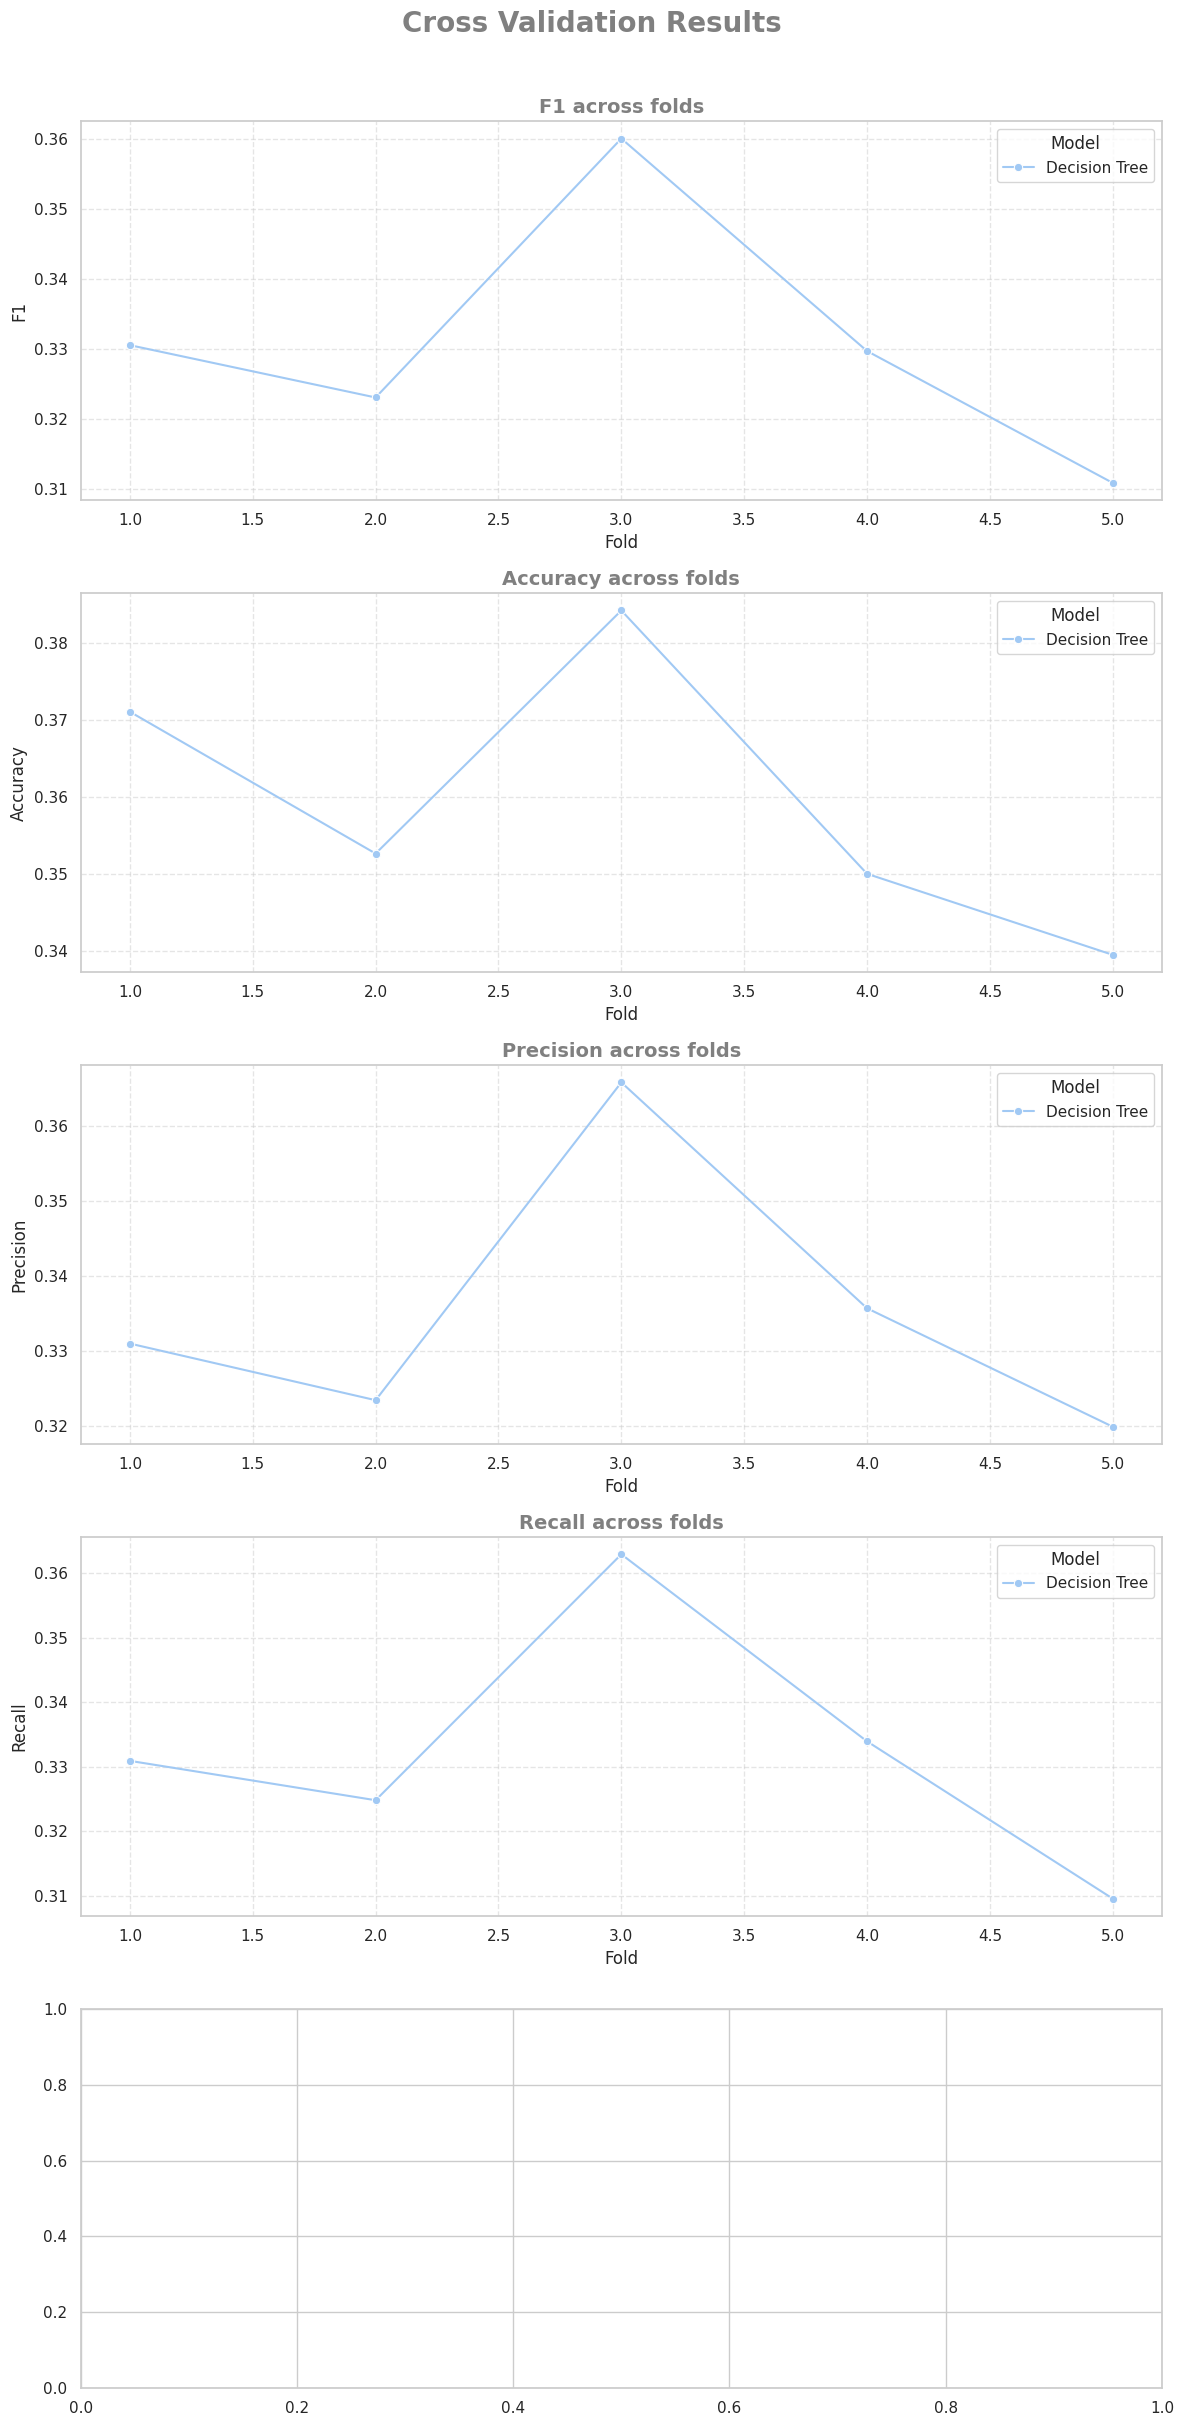

In [559]:
"""
For this part, I just want to see what features are important, while understadning how well a
base model does with the data we have so far.

First I will run cross validation for time series
then i will fit my data to see what features are important
"""
dt = DecisionTreeClassifier(random_state=42)

models = {
    "Decision Tree": dt
}

run_cross_validation(x_train_processed,y_train,models)

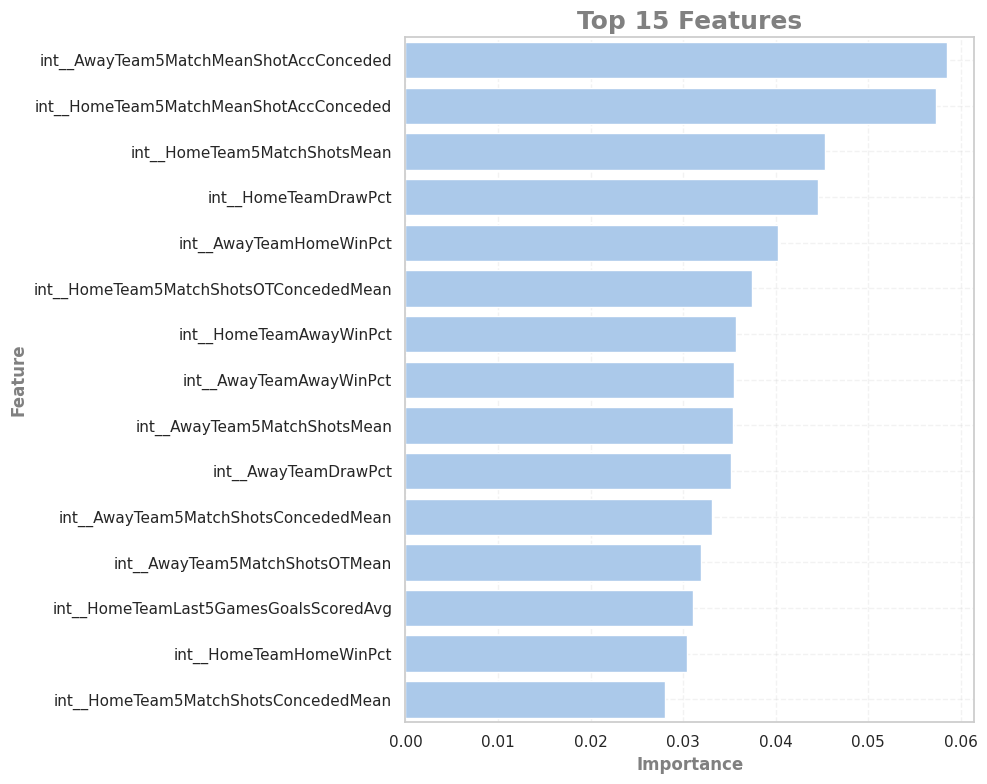

In [560]:
"""
What are the best features?
"""

dt.fit(x_train_processed,y_train)

# show the top best features
feature_importance = dt.feature_importances_
feature_names_ = list(feature_names)

importance_df = (
    pd.DataFrame(
        list(zip(feature_names_,feature_importance)),
        columns=['Feature','Importance'])
)

top15Features = importance_df.sort_values(by='Importance',ascending=False).head(15)

# show results
plt.figure(
    figsize=(10,8)
)

sns.barplot(
    data=top15Features,
    y='Feature',
    x='Importance'
)

# adjust the visual
adjust_visuals(
    'Top 15 Features',
    'Importance',
    'Feature'
)

**Notes**

The base model that we have created is not very good, but provides some key insights:

1. The likely reason for such bad performance is due to the complexity of the dataset -> high bias caused by too many features.
2. The model appears to favour, although not considerably against the other features, the most recent features -> the last 5 games. Does this mean that teams are influenced by most recent results and form?
3. the Feature importance is fairly spread out where there is no single feature that holds the highest weight, which means there is little chance of data leakage!

I will reduce the complexity of the data by applying PCA and see what happens with our base model.

Before PCA: (2280, 79)
After PCA: (2280, 33)


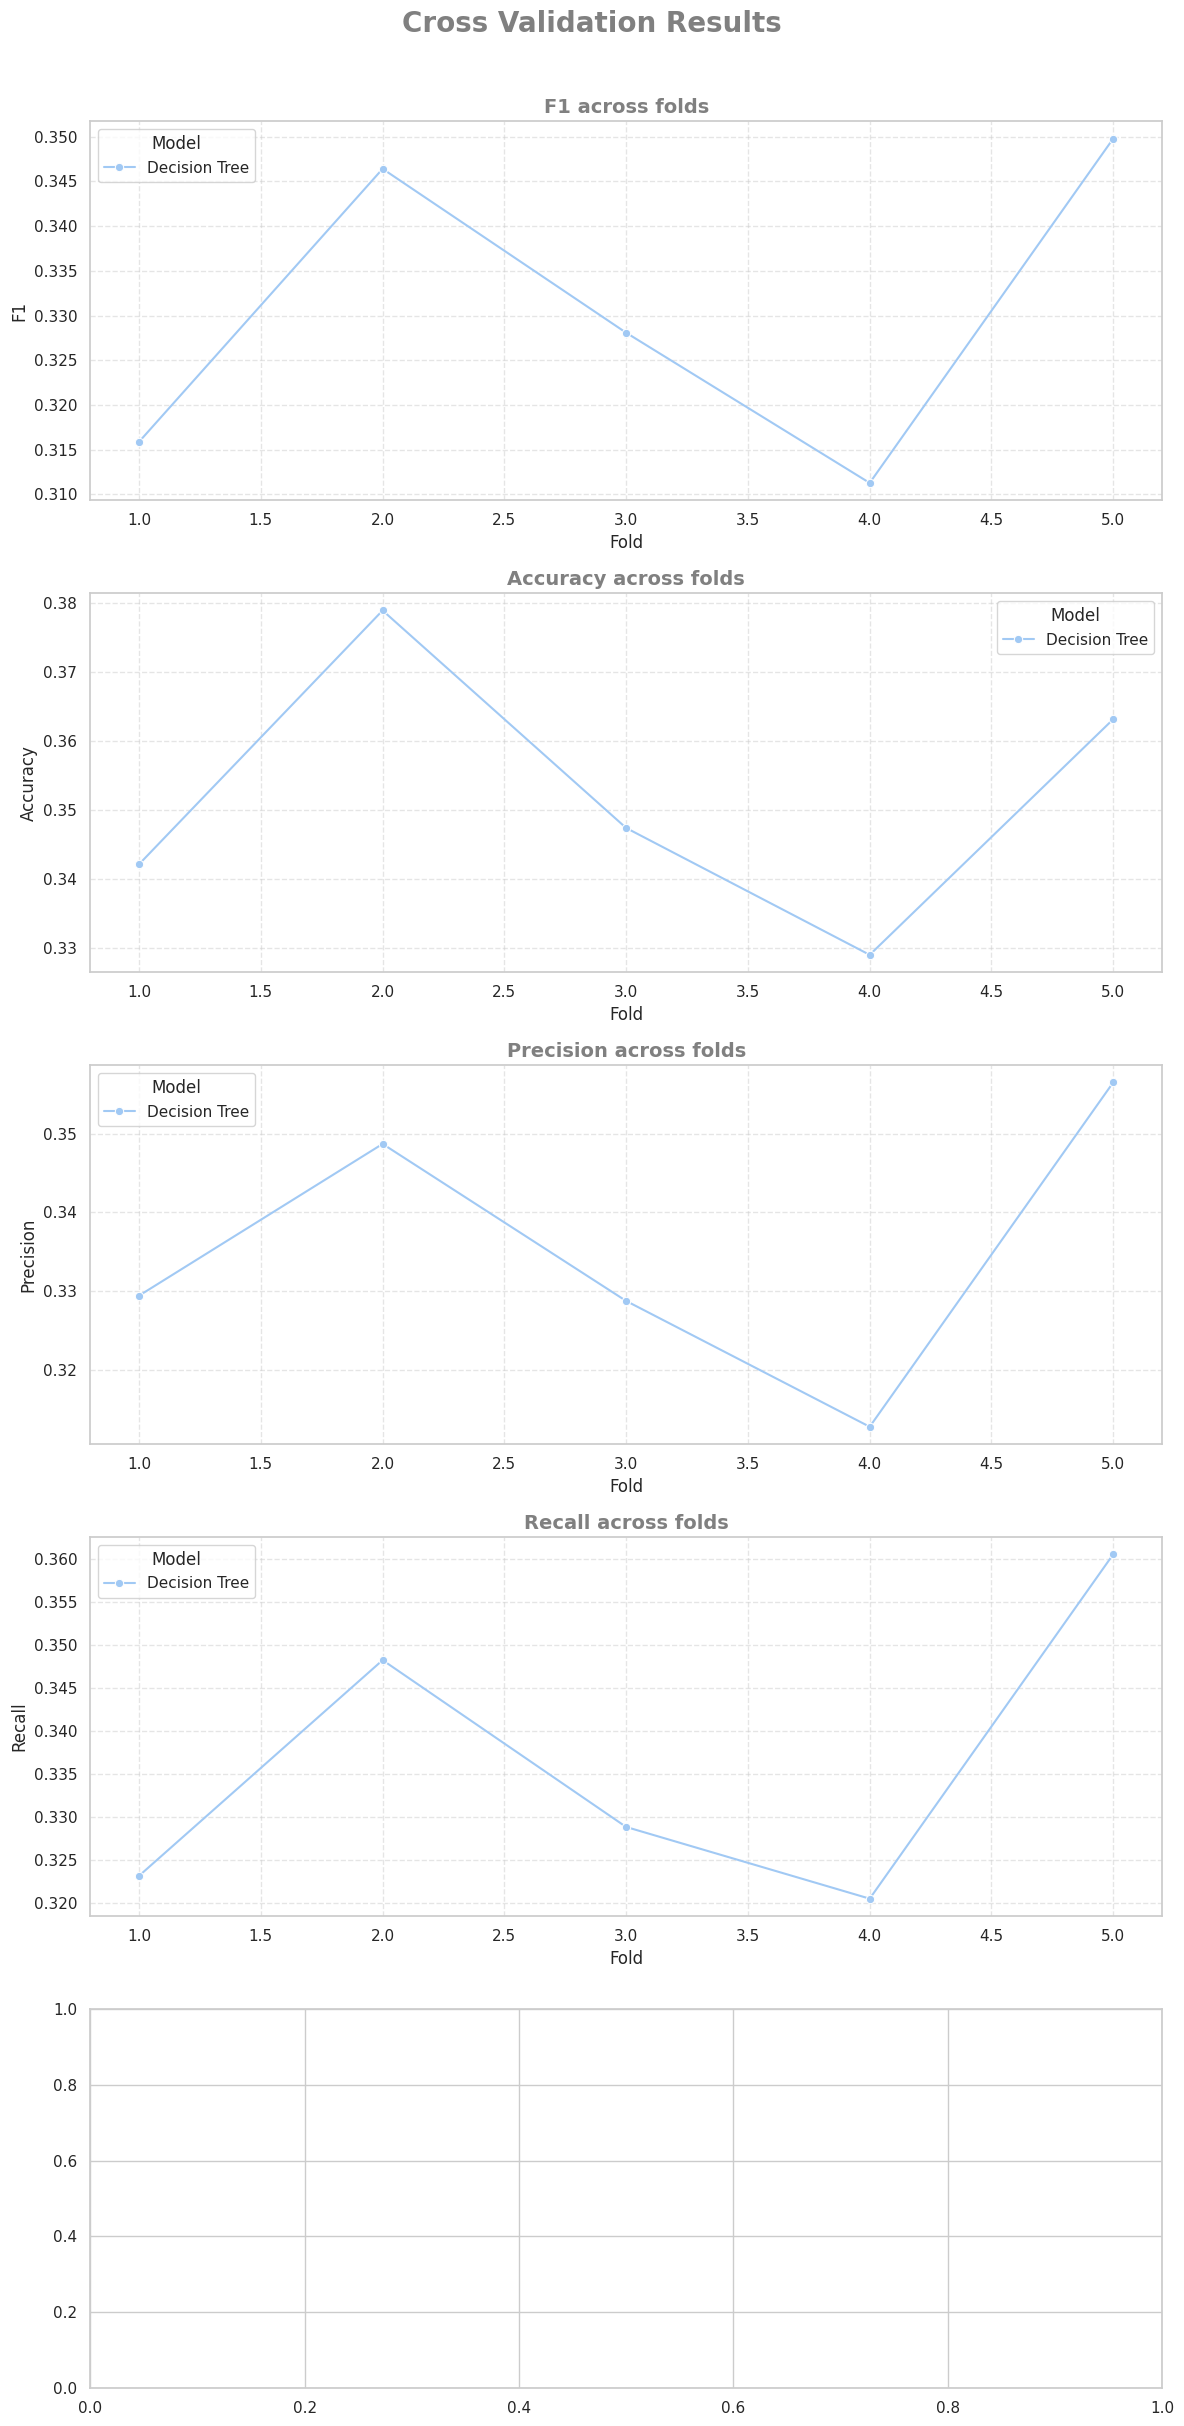

In [561]:
# lets keep 95% of the information
pca = PCA(n_components=0.95)
pca.fit(x_train_processed)
x_train_pca = pca.transform(x_train_processed)

# now lets see the result
print(f"Before PCA: {x_train_processed.shape}")
print(f"After PCA: {x_train_pca.shape}")

# convert the x_train_pca to df
cols = [i for i in range(1,x_train_pca.shape[1]+1)]
x_train_pca_ = pd.DataFrame(x_train_pca,columns=cols)

run_cross_validation(x_train_pca_,y_train,models)

              precision    recall  f1-score   support

           0       0.32      0.28      0.30       132
           1       0.22      0.22      0.22        93
           2       0.42      0.46      0.44       155

    accuracy                           0.34       380
   macro avg       0.32      0.32      0.32       380
weighted avg       0.33      0.34      0.34       380



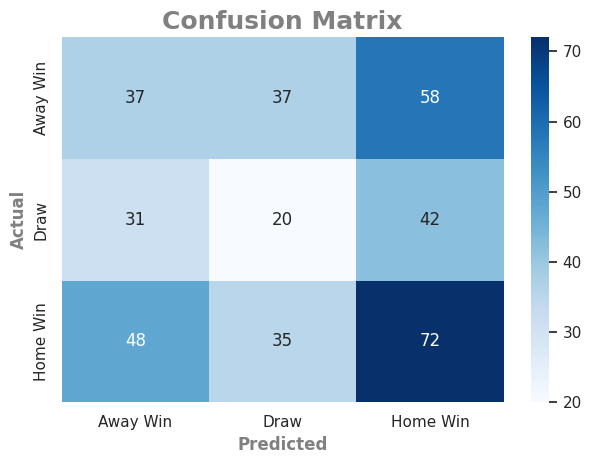

In [565]:
# lets see where our base model is going wrong by using the validation as our
# "test" set.

dt.fit(x_train_processed,y_train)
y_pred = dt.predict(x_val_processed)

# compare with actual
print(classification_report(y_val,y_pred))

# print confusion matrix
target_labels = ['Away Win','Draw','Home Win']
mtx = confusion_matrix(y_val,y_pred)
sns.heatmap(
    mtx,
    annot=True,
    fmt='g',
    cmap='Blues',
    xticklabels=target_labels,
    yticklabels=target_labels
);




#adjust viz
adjust_visuals(
    'Confusion Matrix',
    'Predicted',
    'Actual'

)
